#  Klasifikasi dan Regresi Lokalisasi Indoor Berbasis RSSI Wi-Fi

Tim R&D PT. Sinyal Nusantara sedang mengembangkan layanan navigasi di dalam gedung untuk sebuah kampus besar. GPS tidak andal di dalam ruangan, sehingga posisi pengguna harus diperkirakan dari kekuatan sinyal (RSSI) access point Wi-Fi yang tertangkap ponsel. 
Ibu Laras, manajer produk, ingin tahu apakah sidik jari (fingerprint) RSSI cukup untuk menebak gedung dan lantai pengguna, sekaligus memperkirakan koordinatnya dengan galat sekecil mungkin.

## PROSES 1 — EDA DAN DATA PREPROCESSING

### 1. Import Library

Mengimpor library untuk manipulasi data, visualisasi, statistik, dan preprocessing.

In [1]:
# Cell 1: Import Libraries

import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import VarianceThreshold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings('ignore')

# Konfigurasi visualisasi
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

RANDOM_STATE = 42

print("Library berhasil diimpor.")

Library berhasil diimpor.


### 2. Load dataset
Tujuan: Membaca dataset training dan validation yang sudah disediakan.

In [7]:
train_path = "data/trainingData.csv"
validation_path = "data/validationData.csv"

df_train = pd.read_csv(train_path)
df_validation = pd.read_csv(validation_path)

print("Training Dataset:", df_train.shape)
print("Validation Dataset:", df_validation.shape)

df_train.head()

Training Dataset: (19937, 529)
Validation Dataset: (1111, 529)


,WAP001,WAP002,WAP003,WAP004,WAP005,WAP006,WAP007,WAP008,WAP009,WAP010,...,WAP520,LONGITUDE,LATITUDE,FLOOR,BUILDINGID,SPACEID,RELATIVEPOSITION,USERID,PHONEID,TIMESTAMP
0,100,100,100,100,100,100,100,100,100,100,...,100,-7541.2643,4.864921e+06,2,1,106,2,2,23,1371713733
1,100,100,100,100,100,100,100,100,100,100,...,100,-7536.6212,4.864934e+06,2,1,106,2,2,23,1371713691
2,100,100,100,100,100,100,100,-97,100,100,...,100,-7519.1524,4.864950e+06,2,1,103,2,2,23,1371714095
3,100,100,100,100,100,100,100,100,100,100,...,100,-7524.5704,4.864934e+06,2,1,102,2,2,23,1371713807
4,100,100,100,100,100,100,100,100,100,100,...,100,-7632.1436,4.864982e+06,0,0,122,2,11,13,1369909710


### 3. Identifikasi kolom
Tujuan: Memisahkan fitur RSSI, target, dan metadata.

Disini tidak boleh menggunakan USERID, PHONEID, dan TIMESTAMP sebagai fitur prediksi posisi karena dapat menyebabkan model mempelajari identitas perangkat atau pola waktu, bukan fingerprint Wi-Fi.

Catatan: SPACEID dan RELATIVEPOSITION juga tidak kita gunakan sebagai fitur prediksi utama. Keduanya berpotensi memberikan informasi lokasi secara langsung.

In [8]:
# Fitur RSSI
rssi_features = [
    col for col in df_train.columns
    if col.startswith("WAP")
]

# Target klasifikasi
classification_targets = [
    "BUILDINGID",
    "FLOOR"
]

# Target regresi
regression_targets = [
    "LONGITUDE",
    "LATITUDE"
]

# Metadata
metadata_features = [
    "SPACEID",
    "RELATIVEPOSITION",
    "USERID",
    "PHONEID",
    "TIMESTAMP"
]

print("Jumlah fitur RSSI:", len(rssi_features))
print("Target klasifikasi:", classification_targets)
print("Target regresi:", regression_targets)
print("Metadata:", metadata_features)

assert len(rssi_features) == 520

Jumlah fitur RSSI: 520
Target klasifikasi: ['BUILDINGID', 'FLOOR']
Target regresi: ['LONGITUDE', 'LATITUDE']
Metadata: ['SPACEID', 'RELATIVEPOSITION', 'USERID', 'PHONEID', 'TIMESTAMP']


### 4. Pemeriksaan struktur dataset
Tujuan: Memastikan kedua dataset memiliki struktur kolom yang konsisten dan memahami tipe datanya.

Interpretasi:
- Pastikan semua fitur RSSI memiliki tipe numerik.
- Pastikan target tersedia di kedua dataset.
- Pastikan tidak terdapat perbedaan nama kolom.
- Jika terdapat tipe data tidak sesuai, lakukan konversi sebelum preprocessing.

In [71]:
# Pemeriksaan Struktur Training Dataset

print("=== TRAINING DATA ===")
df_train.info()

print("\n=== TIPE DATA ===")
display(df_train.dtypes.value_counts())

print("\n=== JUMLAH KOLOM ===")
print("Total kolom:", len(df_train.columns))

print("\n=== FITUR RSSI ===")
print("Jumlah fitur RSSI:", len(rssi_features))

print("\n=== TARGET ===")

target_columns = (
    classification_targets + regression_targets
)

display(df_train[target_columns].dtypes)

print("\n=== MISSING TARGET ===")
display(df_train[target_columns].isnull().sum())

=== TRAINING DATA ===
<class 'pandas.DataFrame'>
RangeIndex: 19937 entries, 0 to 19936
Columns: 529 entries, WAP001 to TIMESTAMP
dtypes: float64(2), int64(527)
memory usage: 80.5 MB

=== TIPE DATA ===


int64      527
float64      2
Name: count, dtype: int64


=== JUMLAH KOLOM ===
Total kolom: 529

=== FITUR RSSI ===
Jumlah fitur RSSI: 520

=== TARGET ===


BUILDINGID      int64
FLOOR           int64
LONGITUDE     float64
LATITUDE      float64
dtype: object


=== MISSING TARGET ===


BUILDINGID    0
FLOOR         0
LONGITUDE     0
LATITUDE      0
dtype: int64

### 5. Pemeriksaan duplikasi
Tujuan: Mengidentifikasi baris yang memiliki seluruh nilai sama.

In [72]:
# Pemeriksaan Duplikasi Training

duplicate_train = df_train.duplicated().sum()

duplicate_percentage = (
    duplicate_train / len(df_train) * 100
)

print("Jumlah duplikasi:", duplicate_train)

print(
    "Persentase duplikasi:",
    round(duplicate_percentage, 2),
    "%"
)

Jumlah duplikasi: 637
Persentase duplikasi: 3.2 %


### 6. Missing value aktual
Tujuan: Memeriksa apakah terdapat nilai kosong dalam format NaN.

In [73]:
# Missing Value Analysis

missing_train = df_train.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Count": missing_train,
    "Missing Percentage": (
        missing_train / len(df_train) * 100
    )
})

missing_summary = missing_summary[
    missing_summary["Missing Count"] > 0
]

print(
    "Total missing value:",
    missing_train.sum()
)

display(missing_summary)

Total missing value: 0


,Missing Count,Missing Percentage


### 7. Analisis nilai RSSI +100
Tujuan: Mengukur jumlah dan persentase WAP yang tidak terdeteksi.

In [19]:
rssi_train = df_train[rssi_features]

sentinel_count = (rssi_train == 100).sum()
sentinel_percentage = (rssi_train == 100).mean() * 100

sentinel_summary = pd.DataFrame({
    "WAP": rssi_features,
    "Sentinel Count": sentinel_count.values,
    "Sentinel Percentage": sentinel_percentage.values
})

sentinel_summary = sentinel_summary.sort_values(
    by="Sentinel Percentage",
    ascending=False
)

display(sentinel_summary.head(15))

print(
    "Rata-rata persentase sentinel:",
    round(sentinel_percentage.mean(), 2),
    "%"
)

,WAP,Sentinel Count,Sentinel Percentage
519,WAP520,19937,100.0
496,WAP497,19937,100.0
490,WAP491,19937,100.0
486,WAP487,19937,100.0
487,WAP488,19937,100.0
484,WAP485,19937,100.0
481,WAP482,19937,100.0
246,WAP247,19937,100.0
450,WAP451,19937,100.0
457,WAP458,19937,100.0


Rata-rata persentase sentinel: 96.54 %


### 8. Visualisasi Missing RSSI

Visualisasi ini membantu mengetahui apakah sebagian besar access point memiliki tingkat deteksi yang sangat rendah.
informasi ini digunakan untuk menentukan strategi seleksi fitur.

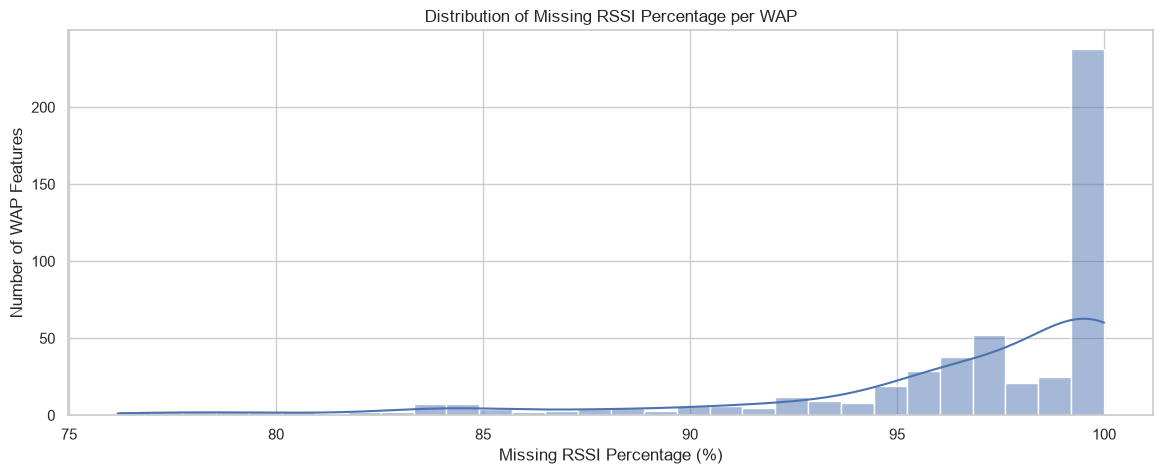

In [20]:
plt.figure(figsize=(14, 5))

sns.histplot(
    sentinel_percentage,
    bins=30,
    kde=True
)

plt.title("Distribution of Missing RSSI Percentage per WAP")
plt.xlabel("Missing RSSI Percentage (%)")
plt.ylabel("Number of WAP Features")

plt.show()

### 9. Identifikasi WAP konstan
Tujuan: Menemukan fitur yang tidak memiliki variasi informasi.

pada bagian ini akan membandingkan dua skenario:
- Full features: seluruh 520 fitur RSSI.
- Reduced features: fitur konstan dihapus.

Penghapusan fitur konstan dilakukan berdasarkan training saja.

In [21]:
constant_features = [
    col for col in rssi_features
    if df_train[col].nunique() == 1
]

print("Jumlah fitur konstan:", len(constant_features))
print("Daftar fitur konstan:")
print(constant_features)

print(
    "Persentase fitur konstan:",
    round(len(constant_features) / len(rssi_features) * 100, 2),
    "%"
)

Jumlah fitur konstan: 55
Daftar fitur konstan:
['WAP003', 'WAP004', 'WAP092', 'WAP093', 'WAP094', 'WAP095', 'WAP152', 'WAP158', 'WAP159', 'WAP160', 'WAP215', 'WAP217', 'WAP226', 'WAP227', 'WAP238', 'WAP239', 'WAP240', 'WAP241', 'WAP242', 'WAP243', 'WAP244', 'WAP245', 'WAP246', 'WAP247', 'WAP254', 'WAP293', 'WAP296', 'WAP301', 'WAP303', 'WAP304', 'WAP307', 'WAP333', 'WAP349', 'WAP353', 'WAP360', 'WAP365', 'WAP416', 'WAP419', 'WAP423', 'WAP429', 'WAP433', 'WAP438', 'WAP441', 'WAP442', 'WAP444', 'WAP445', 'WAP451', 'WAP458', 'WAP482', 'WAP485', 'WAP487', 'WAP488', 'WAP491', 'WAP497', 'WAP520']
Persentase fitur konstan: 10.58 %


### 10. Distribusi BUILDINGID
Tujuan: Mengetahui jumlah sampel setiap kelas gedung.

BUILDINGID
0    5249
1    5196
2    9492
Name: count, dtype: int64


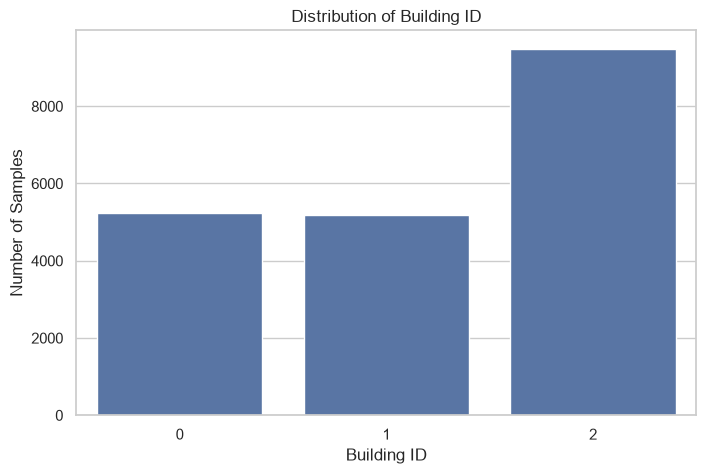

In [22]:
building_counts = df_train["BUILDINGID"].value_counts().sort_index()

print(building_counts)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_train,
    x="BUILDINGID",
    order=sorted(df_train["BUILDINGID"].unique())
)

plt.title("Distribution of Building ID")
plt.xlabel("Building ID")
plt.ylabel("Number of Samples")

plt.show()

### 11. Distribusi FLOOR
Tujuan: Memeriksa distribusi kelas lantai.

FLOOR
0    4369
1    5002
2    4416
3    5048
4    1102
Name: count, dtype: int64


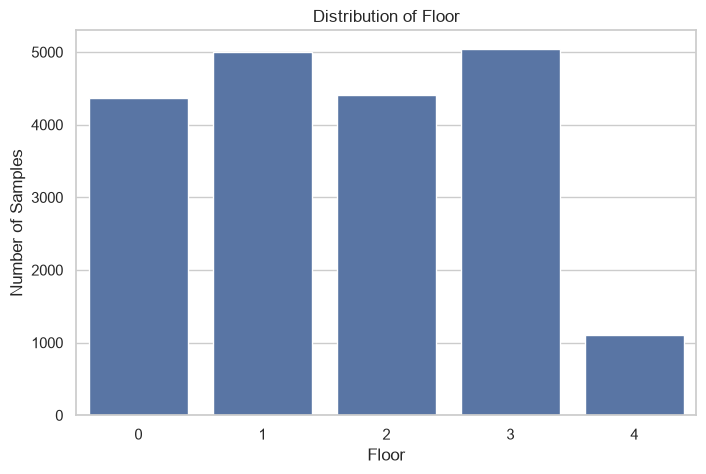

In [23]:
floor_counts = df_train["FLOOR"].value_counts().sort_index()

print(floor_counts)

plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_train,
    x="FLOOR",
    order=sorted(df_train["FLOOR"].unique())
)

plt.title("Distribution of Floor")
plt.xlabel("Floor")
plt.ylabel("Number of Samples")

plt.show()

### 12. Statistik deskriptif RSSI
Tujuan: Mengetahui karakteristik nilai RSSI, termasuk nilai minimum, maksimum, rata-rata, median, dan standar deviasi.

Penting: nilai +100 masih dianggap sebagai sentinel, sehingga kita keluarkan sementara dari statistik RSSI aktual.

Interpretasi:
- mean: rata-rata kekuatan sinyal.
- std: variasi kekuatan sinyal.
- min dan max: rentang nilai RSSI yang terdeteksi.
- 50%: median RSSI.

Nilai count menunjukkan jumlah observasi RSSI yang benar-benar terdeteksi.

In [ ]:
rssi_clean_eda = df_train[rssi_features].replace(100, np.nan)

rssi_statistics = rssi_clean_eda.describe().T


rssi_statistics[
     ["count", "mean", "std", "min", "25%", "50%", "75%", "max"]
].round(2)


,count,mean,std,min,25%,50%,75%,max
WAP001,18.0,-95.33,1.14,-97.0,-96.0,-96.0,-94.25,-93.0
WAP002,19.0,-87.89,2.05,-90.0,-90.0,-86.0,-86.00,-86.0
WAP003,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WAP004,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
WAP005,40.0,-92.52,2.15,-97.0,-94.0,-92.0,-91.75,-89.0
...,...,...,...,...,...,...,...,...
WAP516,3038.0,-72.56,14.61,-101.0,-84.0,-74.0,-63.00,0.0
WAP517,4543.0,-76.02,12.06,-101.0,-85.0,-77.0,-70.00,0.0
WAP518,22.0,-91.55,3.73,-97.0,-95.0,-91.0,-88.00,-87.0
WAP519,3.0,-96.00,1.73,-97.0,-97.0,-97.0,-95.50,-94.0


### 13. Distribusi nilai RSSI
Tujuan: Melihat pola distribusi kekuatan sinyal Wi-Fi.

Interpretasi:
Distribusi ini membantu mengetahui rentang RSSI yang paling sering diterima perangkat.
Semakin mendekati 0 dBm, sinyal semakin kuat. Semakin negatif nilainya, sinyal semakin lemah.

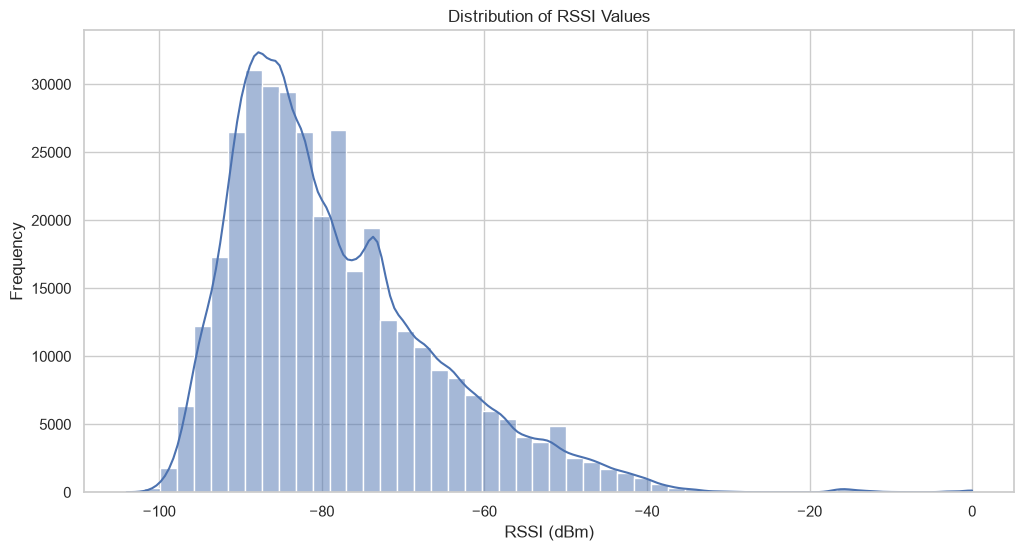

In [28]:
rssi_values = rssi_clean_eda.values.flatten()
rssi_values = rssi_values[~np.isnan(rssi_values)]

plt.figure(figsize=(12, 6))

sns.histplot(
    rssi_values,
    bins=50,
    kde=True
)

plt.title("Distribution of RSSI Values")
plt.xlabel("RSSI (dBm)")
plt.ylabel("Frequency")

plt.show()

### 14. Distribusi RSSI berdasarkan gedung
Tujuan: Mengidentifikasi apakah karakteristik fingerprint RSSI berbeda antar gedung.

Interpretasi:
Apabila distribusi RSSI berbeda antar gedung, fingerprint Wi-Fi berpotensi memberikan informasi yang berguna untuk klasifikasi gedung.

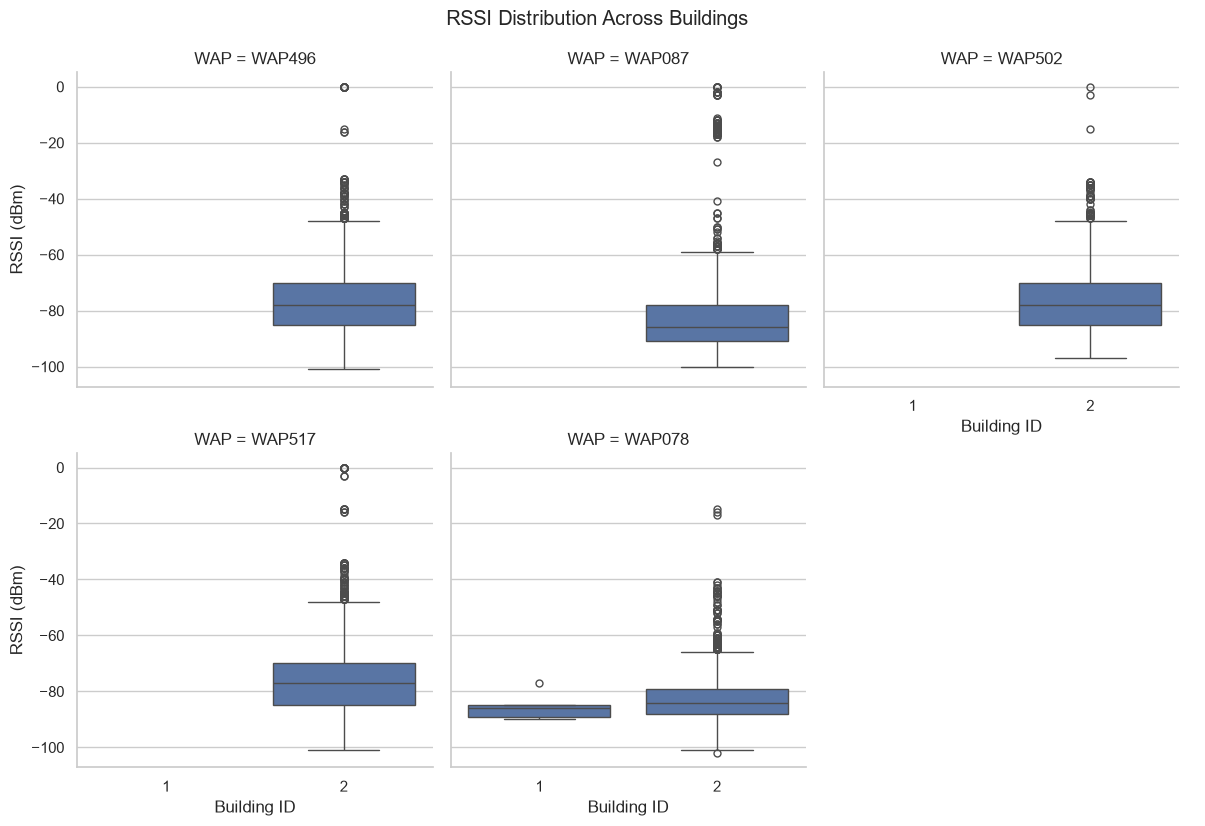

In [29]:
sample_size = min(5, len(rssi_features))

selected_waps = (
    df_train[rssi_features]
    .replace(100, np.nan)
    .notna()
    .sum()
    .sort_values(ascending=False)
    .head(sample_size)
    .index
)

plot_data = df_train[
    list(selected_waps) + ["BUILDINGID"]
].melt(
    id_vars="BUILDINGID",
    var_name="WAP",
    value_name="RSSI"
)

plot_data = plot_data[plot_data["RSSI"] != 100]

g = sns.catplot(
    data=plot_data,
    x="BUILDINGID",
    y="RSSI",
    col="WAP",
    kind="box",
    col_wrap=3,
    height=4,
    sharey=True
)

g.set_axis_labels("Building ID", "RSSI (dBm)")
g.fig.suptitle(
    "RSSI Distribution Across Buildings",
    y=1.03
)

plt.show()

### 15. Deteksi outlier menggunakan IQR
Tujuan: Mengidentifikasi nilai RSSI ekstrem menggunakan metode Interquartile Range (IQR).

Rumus:

IQR = Q3 - Q1

Lower = Q1 - 1,5(IQR)

Upper = Q3 + 1,5(IQR)

ini berfungsi untuk menghitung outlier hanya dari RSSI yang terdeteksi, bukan sentinel +100.

Dalam konteks RSSI, nilai ekstrem dapat menjadi karakteristik fingerprint suatu lokasi. Dalam hal ini harus membedakan anomali pengukuran dengan variasi sinyal yang memang valid.

In [32]:
outlier_results = []

for col in rssi_features:

    values = df_train[col]
    values = values[values != 100]

    if len(values) == 0:
        continue

    Q1 = values.quantile(0.25)
    Q3 = values.quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = (
        (values < lower_bound) |
        (values > upper_bound)
    ).sum()

    outlier_results.append({
        "WAP": col,
        "Q1": Q1,
        "Q3": Q3,
        "IQR": IQR,
        "Lower Bound": lower_bound,
        "Upper Bound": upper_bound,
        "Outlier Count": outliers,
        "Outlier Percentage": outliers / len(values) * 100
    })

outlier_df = pd.DataFrame(outlier_results)


outlier_df.sort_values(
    "Outlier Percentage",
     ascending=False
 ).head(20).round(2)


,WAP,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier Percentage
419,WAP468,-95.00,-95.0,0.00,-95.00,-95.00,4,44.44
310,WAP343,-88.00,-88.0,0.00,-88.00,-88.00,3,33.33
204,WAP216,-85.00,-82.5,2.50,-88.75,-78.75,3,30.00
299,WAP331,-88.75,-88.0,0.75,-89.88,-86.88,3,25.00
385,WAP425,-91.25,-91.0,0.25,-91.62,-90.62,2,25.00
183,WAP194,-63.25,-51.5,11.75,-80.88,-33.88,2,25.00
362,WAP399,-85.00,-84.0,1.00,-86.50,-82.50,12,23.53
277,WAP309,-87.00,-87.0,0.00,-87.00,-87.00,2,22.22
152,WAP163,-89.00,-88.0,1.00,-90.50,-86.50,5,20.83
422,WAP471,-91.00,-91.0,0.00,-91.00,-91.00,1,20.00


### 16. Visualisasi outlier



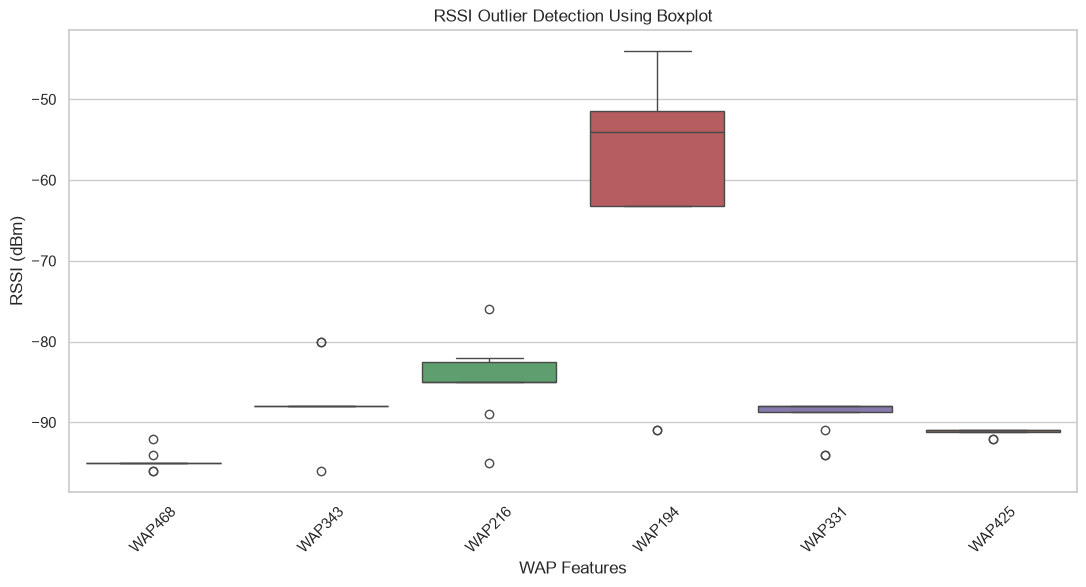

In [33]:
selected_outlier_waps = outlier_df.nlargest(
    6,
    "Outlier Percentage"
)["WAP"].tolist()

boxplot_data = df_train[selected_outlier_waps].replace(
    100,
    np.nan
)

plt.figure(figsize=(13, 6))

sns.boxplot(data=boxplot_data)

plt.title("RSSI Outlier Detection Using Boxplot")
plt.xlabel("WAP Features")
plt.ylabel("RSSI (dBm)")

plt.xticks(rotation=45)
plt.show()

### 17. Korelasi antarfitur RSSI
Tujuan: Mengetahui hubungan antar-WAP. Fitur yang memiliki korelasi tinggi mungkin membawa informasi yang serupa.

Untuk menjaga visualisasi tetap terbaca, gunakan 30 WAP dengan variasi terbesar setelah sentinel diubah menjadi NaN.

Interpretasi:
- Korelasi mendekati +1: hubungan positif kuat.
- Korelasi mendekati -1: hubungan negatif kuat.
- Korelasi mendekati 0: hubungan linear lemah.

Korelasi tinggi tidak otomatis berarti salah satu fitur harus dihapus.

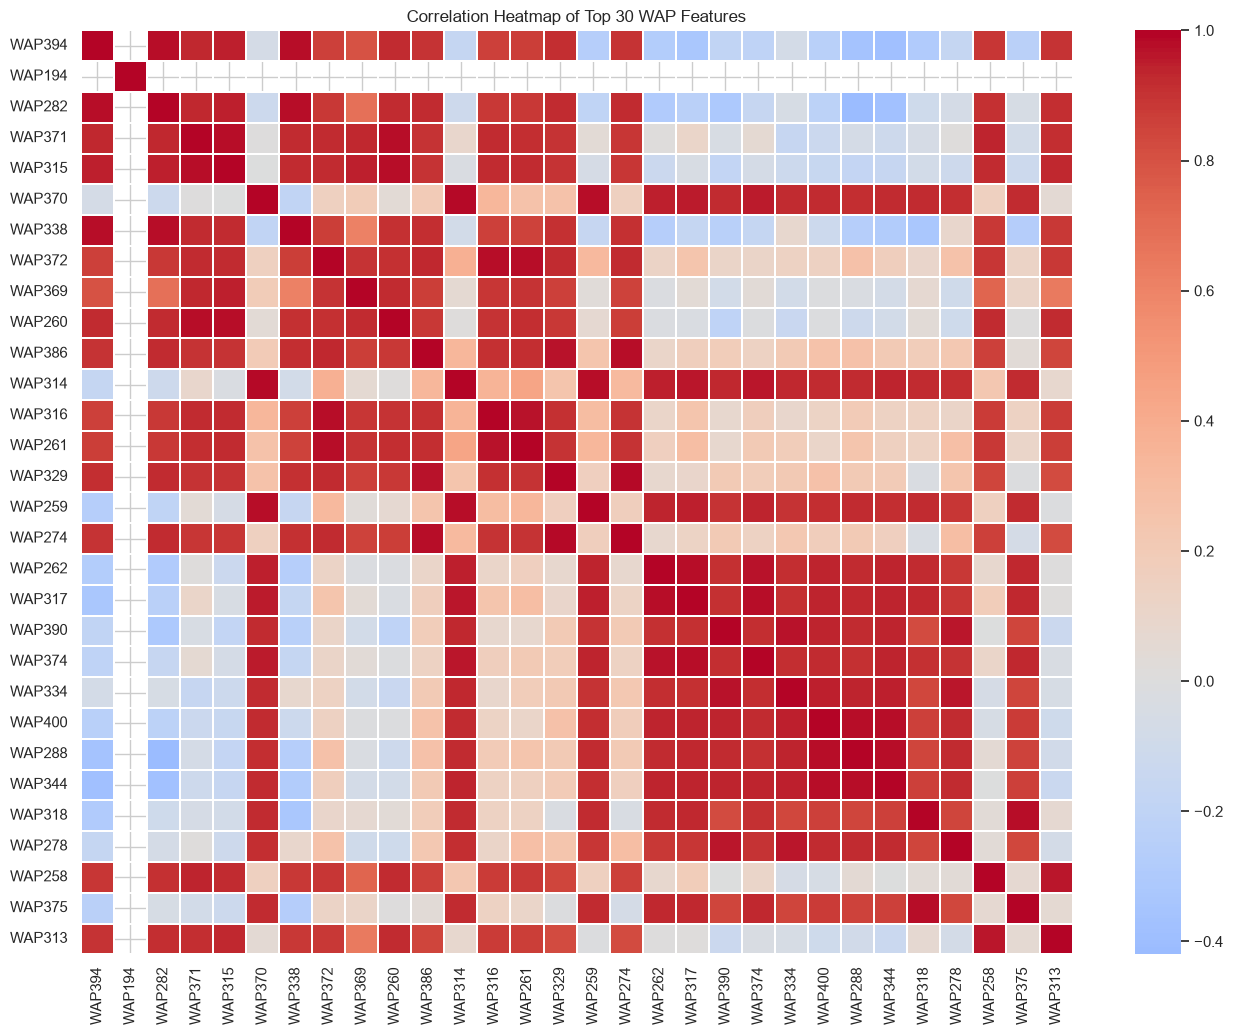

In [34]:
rssi_variance = (
    rssi_clean_eda
    .var()
    .sort_values(ascending=False)
)

top_30_waps = rssi_variance.head(30).index

correlation_matrix = (
    rssi_clean_eda[top_30_waps]
    .corr()
)

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.1
)

plt.title("Correlation Heatmap of Top 30 WAP Features")
plt.show()

### 18. Korelasi fitur dengan koordinat
Tujuan: Mengevaluasi hubungan linear RSSI dengan koordinat LONGITUDE dan LATITUDE.

Catatan: Korelasi Pearson hanya mengukur hubungan linear. Hubungan spasial yang lebih kompleks belum tentu terlihat melalui korelasi ini.

,LONGITUDE,LATITUDE
WAP262,0.439177,-0.489087
WAP344,0.415378,-0.581264
WAP288,0.412118,-0.473359
WAP374,0.406807,-0.471106
WAP400,0.394403,-0.506262
WAP317,0.373258,-0.439291
WAP334,0.248633,-0.563733
WAP314,0.221638,-0.479916
WAP390,0.198862,-0.568921
WAP375,0.180140,-0.223652


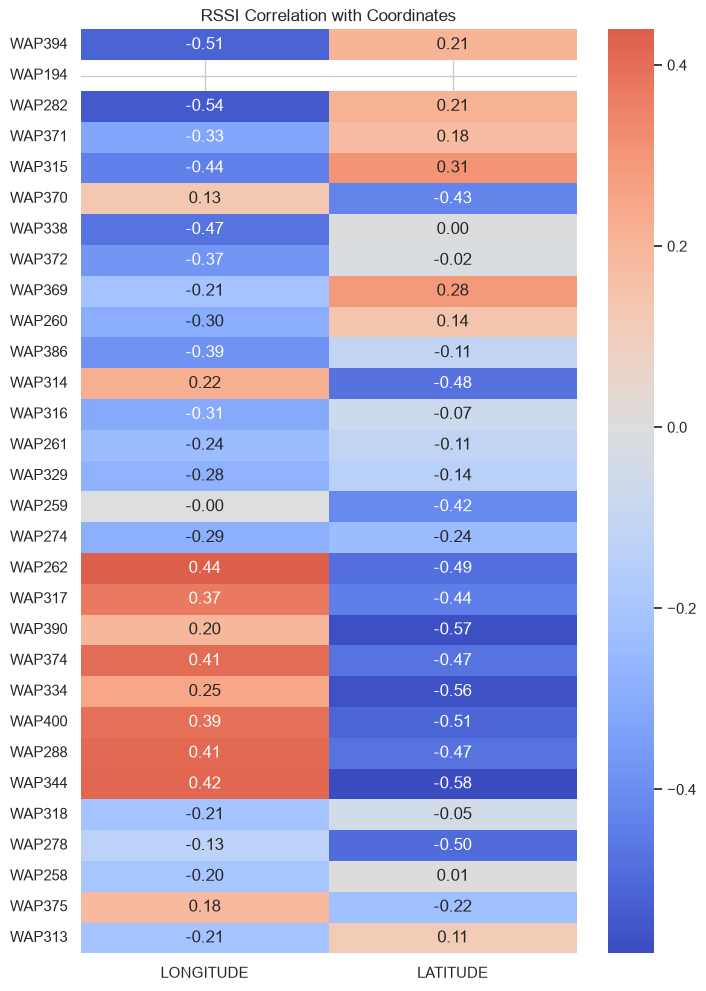

In [38]:
correlation_data = df_train[
    list(top_30_waps) + [
        "LONGITUDE",
        "LATITUDE"
    ]
].replace(100, np.nan)

target_correlation = (
    correlation_data.corr()[["LONGITUDE", "LATITUDE"]]
    .iloc[:-2]
)

display(
    target_correlation
    .sort_values("LONGITUDE", ascending=False)
    .head(15)
)

plt.figure(figsize=(8, 12))

sns.heatmap(
    target_correlation,
    cmap="coolwarm",
    center=0,
    annot=True,
    fmt=".2f"
)

plt.title("RSSI Correlation with Coordinates")
plt.show()

### 19. Distribusi koordinat LONGITUDE dan LATITUDE
Tujuan: Memahami sebaran posisi pengguna berdasarkan koordinat geografis.

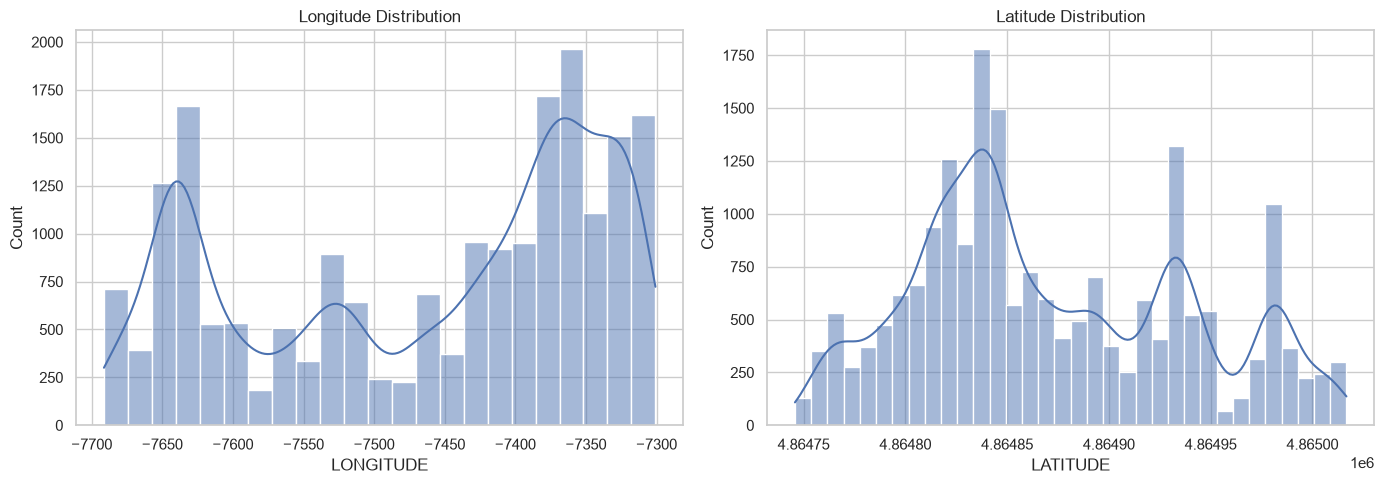

In [39]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    df_train["LONGITUDE"],
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Longitude Distribution")

sns.histplot(
    df_train["LATITUDE"],
    kde=True,
    ax=axes[1]
)

axes[1].set_title("Latitude Distribution")

plt.tight_layout()
plt.show()

### 20. Visualisasi sebaran lokasi

Interpretasi:

Visualisasi ini membantu melihat apakah koordinat antar gedung membentuk kelompok spasial yang berbeda.

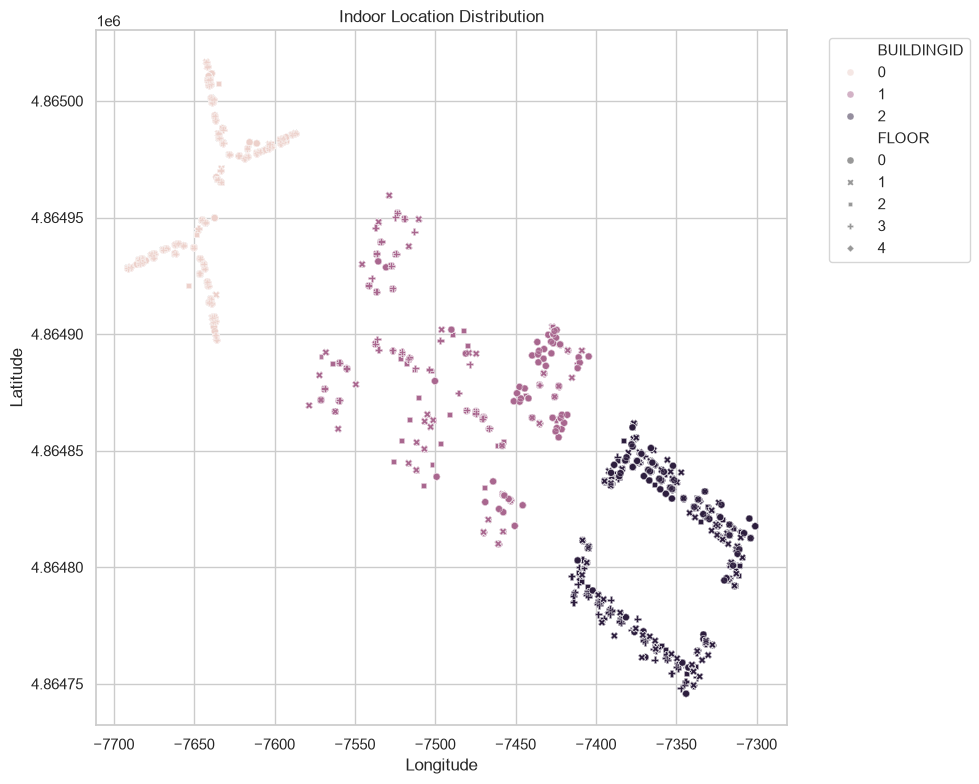

In [40]:
plt.figure(figsize=(10, 8))

sns.scatterplot(
    data=df_train,
    x="LONGITUDE",
    y="LATITUDE",
    hue="BUILDINGID",
    style="FLOOR",
    alpha=0.5,
    s=25
)

plt.title("Indoor Location Distribution")
plt.xlabel("Longitude")
plt.ylabel("Latitude")

plt.legend(
    bbox_to_anchor=(1.05, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

### 21. Membuat salinan dataset
Tujuan: Mempertahankan dataset asli agar tidak berubah selama proses preprocessing.

In [63]:
X_train_raw = df_train[rssi_features].copy()

y_train = df_train[
    ["BUILDINGID", "FLOOR", "LONGITUDE", "LATITUDE"]
].copy()

print("Training features:", X_train_raw.shape)
print("Training targets:", y_train.shape)

print("\nJumlah fitur RSSI:", X_train_raw.shape[1])
print("Jumlah data training:", X_train_raw.shape[0])

print("\nDataset asli tetap dipertahankan.")

Training features: (19937, 520)
Training targets: (19937, 4)

Jumlah fitur RSSI: 520
Jumlah data training: 19937

Dataset asli tetap dipertahankan.


### 22. Metode 1: Sentinel replacement (-105 dBm)
Tujuan: Mengganti nilai +100 dengan -105 dBm.

Alasannya:
- RSSI yang tidak terdeteksi bukan berarti sinyal kuat.
- Nilai -105 dBm berada sedikit di bawah batas minimum RSSI yang tercatat.
- Metode ini mempertahankan informasi bahwa WAP tidak terdeteksi melalui nilai yang sangat rendah.

Catatan: Metode ini tidak memerlukan proses fitting. Namun, -105 merupakan keputusan domain yang perlu diuji dampaknya terhadap performa model.

In [ ]:
def replace_sentinel(X):
    """
    Mengganti nilai sentinel +100 menjadi -105 dBm.
    Fungsi ini tidak melakukan fitting parameter.
    """

    return X.replace(100, -105)

### 23. Metode 2: Sentinel menjadi NaN dan imputasi median
Tujuan: Mengganti nilai tidak terdeteksi menjadi NaN, lalu mengisi nilai tersebut menggunakan median setiap WAP.

Median dihitung hanya dari data training pada setiap skenario pembagian data.

Data test internal menggunakan median yang diperoleh dari data training terkait melalui transformasi pipeline.

Pada evaluasi akhir, validation dataset menggunakan parameter imputasi yang dipelajari ketika model terbaik dilatih ulang menggunakan seluruh training dataset.

In [66]:
def convert_sentinel_to_nan(X):
    """
    Mengubah nilai sentinel +100 menjadi NaN.
    Imputasi median akan dilakukan di dalam pipeline.
    """

    return X.replace(100, np.nan)

### 24. Membandingkan kedua metode
Tujuan: Membandingkan dua strategi penanganan nilai RSSI yang tidak terdeteksi, yaitu Sentinel Replacement (-105 dBm) dan Median Imputation.

Kedua metode akan diuji menggunakan skenario pembagian data 80:20 dan 70:30.

Metode evaluasi:
1. Membandingkan karakteristik statistik hasil preprocessing.
2. Membandingkan performa model klasifikasi dan regresi.
3. Menggunakan metrik evaluasi yang sesuai dengan masing-masing tugas.

Perbandingan statistik deskriptif dilakukan pada data training setelah penanganan sentinel, tetapi sebelum scaling. Statistik yang dibandingkan meliputi mean, standar deviasi, nilai minimum, dan maksimum.

Parameter median hanya dihitung dari data training pada masing-masing skenario split. Data testing hanya digunakan untuk transformasi, bukan untuk menghitung parameter preprocessing.

Interpretasi: Perubahan statistik deskriptif memberikan gambaran mengenai karakteristik data setelah preprocessing. Namun, metode terbaik ditentukan berdasarkan hasil evaluasi model, bukan hanya berdasarkan nilai mean atau standar deviasi.

Tidak ada metode yang diasumsikan lebih baik sebelum eksperimen dilakukan.

### 25. Menghapus fitur konstan
Tujuan: Mengidentifikasi dan menangani fitur RSSI yang tidak memiliki variasi pada data training.

Metode: Seleksi fitur konstan dilakukan menggunakan VarianceThreshold di dalam pipeline preprocessing.

Seleksi fitur hanya di-fit menggunakan data training pada setiap skenario pembagian data. Data test internal menggunakan hasil seleksi fitur yang sama melalui transformasi.

Alasan metodologis: Fitur yang tidak memiliki variasi pada data training tidak memberikan informasi pembeda berdasarkan nilai fitur tersebut. Seleksi di dalam pipeline juga mencegah kebocoran informasi dari data test.

Jumlah fitur yang tersisa ditentukan berdasarkan hasil seleksi pada masing-masing skenario eksperimen.

### 26. Perbandingan Full Features dan Reduced Features

Penelitian ini membandingkan dua skenario penggunaan fitur:

1. Full features: menggunakan seluruh 520 fitur RSSI Wi-Fi.
2. Reduced features: mengurangi fitur menggunakan VarianceThreshold dengan threshold 0.0.

VarianceThreshold digunakan untuk menghapus fitur yang memiliki variansi nol pada data training. Fitur konstan tidak memberikan informasi pembeda antarobservasi sehingga dapat dihilangkan.

Berdasarkan pengujian preprocessing, diperoleh hasil:

- Split 80:20:
  - Metode sentinel: 520 menjadi 460 fitur.
  - Metode median: 520 menjadi 424 fitur.
- Split 70:30:
  - Metode sentinel: 520 menjadi 460 fitur.
  - Metode median: 520 menjadi 419 fitur.

Perbedaan jumlah fitur setelah reduksi menunjukkan bahwa hasil transformasi data memengaruhi fitur yang dipertahankan oleh VarianceThreshold.

Perbandingan ini dilakukan untuk mengetahui pengaruh metode preprocessing terhadap jumlah fitur. Penentuan apakah reduksi fitur meningkatkan performa prediksi akan dilakukan pada tahap eksperimen model.

### 27. Identifikasi dan Penanganan Target Kategorikal

Tujuan: Mengidentifikasi fitur kategorikal dan menentukan kebutuhan encoding berdasarkan karakteristik dataset.

Fitur input utama pada penelitian ini terdiri dari 520 fitur RSSI Wi-Fi yang seluruhnya berbentuk numerik sehingga tidak memerlukan proses encoding.

BUILDINGID dan FLOOR merupakan target klasifikasi yang sudah direpresentasikan menggunakan label numerik pada dataset asli.

Oleh karena itu, Label Encoding tidak diperlukan dan label asli dipertahankan untuk menjaga interpretasi kelas.

Kolom SPACEID, RELATIVEPOSITION, USERID, PHONEID, dan TIMESTAMP diperlakukan sebagai metadata dan tidak digunakan sebagai fitur input model.

Kesimpulan: Tidak diperlukan encoding kategorikal pada fitur input utama dalam penelitian ini.

### 28. Menghitung imbalance ratio

Tujuan: Mengukur tingkat ketidakseimbangan distribusi kelas pada target BUILDINGID dan FLOOR.

Rumus:

Imbalance Ratio = Jumlah sampel kelas mayoritas / Jumlah sampel kelas minoritas

Interpretasi:

Nilai imbalance ratio sebesar 1 menunjukkan distribusi kelas yang seimbang. Semakin besar nilainya, semakin tinggi tingkat ketidakseimbangan distribusi kelas.

Analisis dilakukan secara terpisah untuk target BUILDINGID dan FLOOR menggunakan training dataset.

HStrategi penanganan imbalance ditentukan berdasarkan distribusi masing-masing target. BUILDINGID menggunakan distribusi asli tanpa resampling, sedangkan FLOOR menggunakan class weighting pada model klasifikasi yang mendukungnya.

Bobot kelas ditentukan berdasarkan data training dan tidak menggunakan informasi dari data test.

In [75]:
def calculate_imbalance(target):

    counts = target.value_counts()

    imbalance_ratio = counts.max() / counts.min()

    result = pd.DataFrame({
        "Class": counts.index,
        "Count": counts.values,
        "Percentage": (
            counts.values / counts.sum()
        ) * 100
    })

    return result, imbalance_ratio


building_balance, building_ir = calculate_imbalance(
    y_train["BUILDINGID"]
)

floor_balance, floor_ir = calculate_imbalance(
    y_train["FLOOR"]
)

print("BUILDING DISTRIBUTION")
display(building_balance)

print("Building Imbalance Ratio:", round(building_ir, 3))

print("\nFLOOR DISTRIBUTION")
display(floor_balance)

print("Floor Imbalance Ratio:", round(floor_ir, 3))

BUILDING DISTRIBUTION


,Class,Count,Percentage
0,2,9492,47.609971
1,0,5249,26.327933
2,1,5196,26.062096


Building Imbalance Ratio: 1.827

FLOOR DISTRIBUTION


,Class,Count,Percentage
0,3,5048,25.319757
1,1,5002,25.089030
2,2,4416,22.149772
3,0,4369,21.914029
4,4,1102,5.527411


Floor Imbalance Ratio: 4.581


### 29. Interpretasi dan Strategi Penanganan Class Imbalance

Berdasarkan hasil pemeriksaan distribusi kelas, BUILDINGID memiliki imbalance ratio sebesar 1,827. Ketiga kelas masih memiliki proporsi yang relatif memadai sehingga tidak dilakukan resampling.

Sementara itu, FLOOR memiliki imbalance ratio sebesar 4,581. Kelas FLOOR 4 hanya mencakup 5,53% dari keseluruhan data training. Kondisi ini menunjukkan ketidakseimbangan kelas yang perlu diperhatikan.

Strategi yang dipilih adalah:
1. BUILDINGID: menggunakan distribusi data asli tanpa resampling.
2. FLOOR: menggunakan class weighting dengan parameter class_weight=balanced pada model klasifikasi yang mendukungnya.

Class weighting akan diterapkan pada tahap pelatihan model. Pendekatan ini memberikan bobot lebih besar kepada kelas minoritas tanpa mengubah jumlah observasi dalam dataset.

Seluruh keputusan penanganan imbalance hanya diterapkan berdasarkan data training. Data test tidak digunakan untuk menentukan bobot kelas.

Visualisasi distribusi kelas menunjukkan kondisi data sebelum penerapan strategi penanganan imbalance. Perbandingan hasil penanganan akan dilakukan pada tahap eksperimen model.

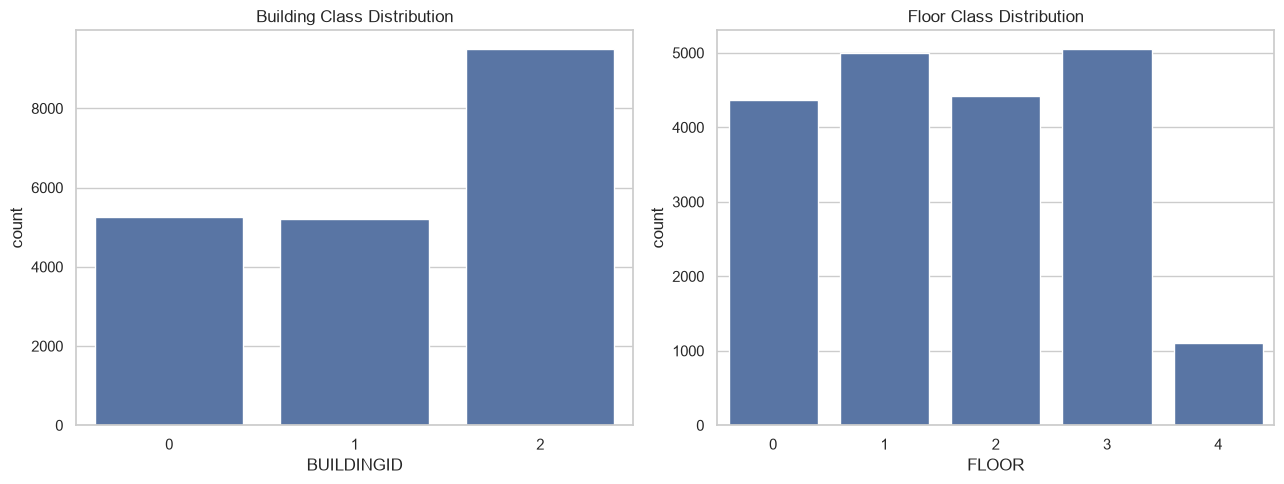

In [57]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(
    data=df_train,
    x="BUILDINGID",
    ax=axes[0]
)

axes[0].set_title("Building Class Distribution")

sns.countplot(
    data=df_train,
    x="FLOOR",
    ax=axes[1]
)

axes[1].set_title("Floor Class Distribution")

plt.tight_layout()
plt.show()

### 30. Membuat Pembagian Data Training dan Testing

Tujuan: Membagi training dataset menjadi data latih dan data uji internal untuk mengevaluasi performa model.

Pembagian data menggunakan dua skenario:
1. 80% data training dan 20% data testing.
2. 70% data training dan 30% data testing.

Metode stratifikasi: Pembagian menggunakan stratifikasi berdasarkan kombinasi BUILDINGID dan FLOOR agar proporsi setiap kombinasi gedung dan lantai tetap terjaga.

Random State: 42.

Data validation bawaan dataset tidak digunakan dalam proses pembagian ini dan disimpan untuk evaluasi akhir.

In [67]:
# Membuat Stratification Target

stratify_target = (
    y_train["BUILDINGID"].astype(str)
    + "_"
    + y_train["FLOOR"].astype(str)
)


# Skenario 1: Pembagian Data 80:20

X_train_80, X_test_80, y_train_80, y_test_80 = train_test_split(
    X_train_raw,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=stratify_target
)


# Skenario 2: Pembagian Data 70:30

X_train_70, X_test_70, y_train_70, y_test_70 = train_test_split(
    X_train_raw,
    y_train,
    test_size=0.30,
    random_state=42,
    stratify=stratify_target
)


# Menampilkan Hasil Pembagian Data

print("=== SKENARIO 80:20 ===")
print("Training:", X_train_80.shape)
print("Testing :", X_test_80.shape)

print("\n=== SKENARIO 70:30 ===")
print("Training:", X_train_70.shape)
print("Testing :", X_test_70.shape)

=== SKENARIO 80:20 ===
Training: (15949, 520)
Testing : (3988, 520)

=== SKENARIO 70:30 ===
Training: (13955, 520)
Testing : (5982, 520)


### 31. Standardisasi Fitur Menggunakan StandardScaler

Tujuan: Menyamakan skala fitur RSSI agar setiap fitur memiliki skala yang lebih sebanding.

StandardScaler melakukan transformasi berdasarkan rata-rata dan standar deviasi yang dihitung dari data training.

Dalam penelitian ini, StandardScaler akan diterapkan di dalam pipeline preprocessing. Parameter scaling hanya dipelajari dari data training pada setiap skenario eksperimen.

Data testing hanya menggunakan parameter transformasi yang telah dipelajari dari data training.

Standardisasi akan dibandingkan dengan MinMaxScaler pada eksperimen model.

### 32. Perbandingan StandardScaler dan MinMaxScaler

Tujuan: Membandingkan dua metode penskalaan fitur, yaitu StandardScaler dan MinMaxScaler.

StandardScaler: Mengubah fitur berdasarkan rata-rata dan standar deviasi data training.

MinMaxScaler: Mengubah rentang fitur berdasarkan nilai minimum dan maksimum data training.

Metode evaluasi:*Kedua scaler dibandingkan melalui eksperimen model dengan skenario preprocessing, pembagian data, dan konfigurasi model yang konsisten.

Alasan metodologis: Pemilihan scaler tidak hanya didasarkan pada statistik hasil transformasi, tetapi juga pada performa model klasifikasi dan regresi.

Seluruh proses scaling dilakukan di dalam pipeline untuk mencegah data leakage.

### 33. Pipeline Preprocessing

Tujuan: Menggabungkan tahapan preprocessing ke dalam satu pipeline agar seluruh parameter preprocessing hanya dipelajari dari data training.

Pipeline mencakup dua metode penanganan nilai RSSI tidak terdeteksi:

1. Sentinel Replacement: Mengganti nilai +100 menjadi -105 dBm.
2. Median Imputation: Mengubah nilai +100 menjadi NaN, kemudian mengisi nilai tersebut menggunakan median setiap fitur berdasarkan data training.

Pipeline juga menyediakan dua skenario fitur:

1. Full Features: Menggunakan seluruh 520 fitur RSSI.
2. Reduced Features: Menghapus fitur konstan menggunakan VarianceThreshold.

Selain itu, digunakan dua alternatif scaling, yaitu StandardScaler dan MinMaxScaler.

Seluruh tahapan preprocessing di-fit menggunakan data training pada setiap skenario eksperimen. Data testing hanya menjalankan transformasi menggunakan parameter yang telah dipelajari dari data training.

Tujuan metodologis: Mencegah data leakage dan memastikan perbandingan metode preprocessing dilakukan secara konsisten.

In [68]:
# Pipeline Preprocessing

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.preprocessing import FunctionTransformer


# Custom Median Imputer
class RSSIMedianImputer(BaseEstimator, TransformerMixin):

    def fit(self, X, y=None):

        X = np.asarray(X, dtype=float)

        self.statistics_ = np.array([
            np.median(col[np.isfinite(col)])
            if np.isfinite(col).any()
            else -105
            for col in X.T
        ])

        return self

    def transform(self, X):

        X = np.asarray(X, dtype=float).copy()

        missing_rows, missing_cols = np.where(np.isnan(X))

        X[missing_rows, missing_cols] = (
            self.statistics_[missing_cols]
        )

        return X


# Pipeline Builder
def build_preprocessing_pipeline(
    method="sentinel",
    feature_mode="full",
    scaler="standard"
):

    steps = []

    # Metode penanganan sentinel
    if method == "sentinel":

        steps.append((
            "sentinel_replacement",
            FunctionTransformer(
                replace_sentinel,
                validate=False
            )
        ))

    elif method == "median":

        steps.append((
            "sentinel_to_nan",
            FunctionTransformer(
                convert_sentinel_to_nan,
                validate=False
            )
        ))

        steps.append((
            "imputer",
            RSSIMedianImputer()
        ))

    else:
        raise ValueError("Metode preprocessing tidak dikenal.")

    # Seleksi fitur
    if feature_mode == "reduced":

        steps.append((
            "selector",
            VarianceThreshold(threshold=0.0)
        ))

    elif feature_mode != "full":

        raise ValueError("Mode fitur tidak dikenal.")

    # Scaling
    if scaler == "standard":

        steps.append((
            "scaler",
            StandardScaler()
        ))

    elif scaler == "minmax":

        steps.append((
            "scaler",
            MinMaxScaler()
        ))

    else:
        raise ValueError("Scaler tidak dikenal.")

    return Pipeline(steps)

In [74]:
# Pengujian Pipeline Preprocessing

results = []

for method in ["sentinel", "median"]:
    for feature_mode in ["full", "reduced"]:
        for scaler in ["standard", "minmax"]:

            pipeline = build_preprocessing_pipeline(
                method=method,
                feature_mode=feature_mode,
                scaler=scaler
            )

            X_train_result = pipeline.fit_transform(X_train_80)

            X_test_result = pipeline.transform(X_test_80)

            # Validasi hasil preprocessing

            assert np.isfinite(X_train_result).all(), (
                "Training mengandung NaN atau Inf."
            )

            assert np.isfinite(X_test_result).all(), (
                "Testing mengandung NaN atau Inf."
            )

            results.append({
                "Method": method,
                "Feature Mode": feature_mode,
                "Scaler": scaler,
                "Training Shape": X_train_result.shape,
                "Testing Shape": X_test_result.shape,
                "Status": "Success"
            })

pipeline_test_results = pd.DataFrame(results)

display(pipeline_test_results)

,Method,Feature Mode,Scaler,Training Shape,Testing Shape,Status
0,sentinel,full,standard,"(15949, 520)","(3988, 520)",Success
1,sentinel,full,minmax,"(15949, 520)","(3988, 520)",Success
2,sentinel,reduced,standard,"(15949, 460)","(3988, 460)",Success
3,sentinel,reduced,minmax,"(15949, 460)","(3988, 460)",Success
4,median,full,standard,"(15949, 520)","(3988, 520)",Success
5,median,full,minmax,"(15949, 520)","(3988, 520)",Success
6,median,reduced,standard,"(15949, 424)","(3988, 424)",Success
7,median,reduced,minmax,"(15949, 424)","(3988, 424)",Success


In [76]:
# Pengujian Pipeline pada Split 70:30

results_70 = []

for method in ["sentinel", "median"]:
    for feature_mode in ["full", "reduced"]:
        for scaler in ["standard", "minmax"]:

            pipeline = build_preprocessing_pipeline(
                method=method,
                feature_mode=feature_mode,
                scaler=scaler
            )

            X_train_result = pipeline.fit_transform(X_train_70)

            X_test_result = pipeline.transform(X_test_70)
            # Validasi hasil preprocessing

            assert np.isfinite(X_train_result).all(), (
                "Training mengandung NaN atau Inf."
            )

            assert np.isfinite(X_test_result).all(), (
                "Testing mengandung NaN atau Inf."
            )

            results_70.append({
                "Method": method,
                "Feature Mode": feature_mode,
                "Scaler": scaler,
                "Training Shape": X_train_result.shape,
                "Testing Shape": X_test_result.shape,
                "Status": "Success"
            })

pipeline_test_70 = pd.DataFrame(results_70)

display(pipeline_test_70)

,Method,Feature Mode,Scaler,Training Shape,Testing Shape,Status
0,sentinel,full,standard,"(13955, 520)","(5982, 520)",Success
1,sentinel,full,minmax,"(13955, 520)","(5982, 520)",Success
2,sentinel,reduced,standard,"(13955, 460)","(5982, 460)",Success
3,sentinel,reduced,minmax,"(13955, 460)","(5982, 460)",Success
4,median,full,standard,"(13955, 520)","(5982, 520)",Success
5,median,full,minmax,"(13955, 520)","(5982, 520)",Success
6,median,reduced,standard,"(13955, 419)","(5982, 419)",Success
7,median,reduced,minmax,"(13955, 419)","(5982, 419)",Success


In [77]:
# Perbandingan Statistik Dua Metode Penanganan RSSI

def compare_rssi_methods(X_train, split_name):

    # Metode 1: Sentinel Replacement
    X_sentinel = replace_sentinel(X_train.copy())

    # Metode 2: Median Imputation
    X_nan = convert_sentinel_to_nan(X_train.copy())

    median_imputer = RSSIMedianImputer()
    X_median = median_imputer.fit_transform(X_nan)

    # Mengubah hasil menjadi DataFrame
    X_sentinel = pd.DataFrame(
        X_sentinel,
        columns=X_train.columns
    )

    X_median = pd.DataFrame(
        X_median,
        columns=X_train.columns
    )

    # Ringkasan statistik
    summary = []

    for method, data in [
        ("Sentinel Replacement", X_sentinel),
        ("Median Imputation", X_median)
    ]:

        summary.append({
            "Split": split_name,
            "Method": method,
            "Mean": data.mean().mean(),
            "Std": data.std().mean(),
            "Minimum": data.min().min(),
            "Maximum": data.max().max()
        })

    return summary


# Perbandingan pada kedua skenario split

comparison_results = []

comparison_results.extend(
    compare_rssi_methods(X_train_80, "80:20")
)

comparison_results.extend(
    compare_rssi_methods(X_train_70, "70:30")
)

rssi_comparison = pd.DataFrame(comparison_results)

display(rssi_comparison.round(3))

,Split,Method,Mean,Std,Minimum,Maximum
0,80:20,Sentinel Replacement,-104.083,3.738,-105.0,0.0
1,80:20,Median Imputation,-86.425,1.522,-105.0,0.0
2,70:30,Sentinel Replacement,-104.084,3.736,-105.0,0.0
3,70:30,Median Imputation,-86.456,1.521,-105.0,0.0


### Interpretasi Hasil Perbandingan Statistik

Berdasarkan hasil perbandingan, median imputation menghasilkan nilai mean RSSI yang lebih tinggi dibandingkan sentinel replacement pada kedua skenario pembagian data.

Standar deviasi pada median imputation juga lebih rendah. Hal ini menunjukkan bahwa penggantian nilai RSSI yang tidak terdeteksi menggunakan median mengubah distribusi nilai dan mengurangi variasi data.

Kedua metode menghasilkan rentang nilai yang sama, yaitu -105 hingga 0 dBm.

Hasil pada split 80:20 dan 70:30 menunjukkan karakteristik statistik yang relatif konsisten.

Namun, perubahan mean dan standar deviasi tidak dapat dijadikan dasar tunggal untuk menentukan metode terbaik. Penentuan metode terbaik tetap memerlukan evaluasi performa model pada tahap eksperimen.

Dengan demikian, kedua metode tetap dipertahankan sebagai alternatif preprocessing untuk dibandingkan lebih lanjut.

## PROSES 2: CLUSTERING

Tahap ini bertujuan mengelompokkan data fingerprint RSSI Wi-Fi berdasarkan kemiripan karakteristik sinyal tanpa menggunakan label target sebagai fitur pembentuk cluster.

Algoritma yang digunakan:
1. K-Means untuk mengelompokkan data berdasarkan jumlah cluster optimal.
2. DBSCAN untuk mengidentifikasi kelompok berdasarkan kepadatan data.

Evaluasi dilakukan menggunakan Silhouette Score, Davies-Bouldin Index, Adjusted Rand Index (ARI), dan Normalized Mutual Information (NMI).

Visualisasi PCA 2D digunakan untuk membantu memahami struktur cluster. Interpretasi fisik dilakukan dengan membandingkan hasil cluster terhadap BUILDINGID, FLOOR, LONGITUDE, dan LATITUDE.

### 34. Persiapan Data Clustering

Tahap ini menyiapkan data RSSI Wi-Fi untuk proses clustering menggunakan K-Means dan DBSCAN.

Konfigurasi utama menggunakan Sentinel Replacement, Reduced Features, dan MinMaxScaler.

Seluruh preprocessing di-fit menggunakan training dataset. BUILDINGID dan FLOOR tidak digunakan sebagai fitur pembentuk cluster, tetapi disimpan sebagai label referensi untuk evaluasi menggunakan ARI dan NMI.

Data validation tidak digunakan dalam proses clustering ini.

In [78]:

# 1. Membuat pipeline preprocessing
clustering_preprocessor = build_preprocessing_pipeline(
    method="sentinel",
    feature_mode="reduced",
    scaler="minmax"
)

# 2. Fit preprocessing pada seluruh training dataset
X_cluster = clustering_preprocessor.fit_transform(X_train_raw)

# 3. Menyimpan label asli untuk evaluasi
y_cluster_building = y_train["BUILDINGID"].reset_index(drop=True)
y_cluster_floor = y_train["FLOOR"].reset_index(drop=True)

# 4. Pemeriksaan hasil
print("=== DATA CLUSTERING ===")
print("Jumlah observasi:", X_cluster.shape[0])
print("Jumlah fitur:", X_cluster.shape[1])

print("\n=== LABEL REFERENSI ===")
print("BUILDINGID:", y_cluster_building.shape)
print("FLOOR:", y_cluster_floor.shape)

print("\n=== VALIDASI DATA ===")
print("Mengandung NaN:", np.isnan(X_cluster).any())
print("Mengandung Inf:", np.isinf(X_cluster).any())

=== DATA CLUSTERING ===
Jumlah observasi: 19937
Jumlah fitur: 465

=== LABEL REFERENSI ===
BUILDINGID: (19937,)
FLOOR: (19937,)

=== VALIDASI DATA ===
Mengandung NaN: False
Mengandung Inf: False


### 35. Penentuan Jumlah Cluster K-Means

K-Means digunakan untuk mengelompokkan fingerprint RSSI Wi-Fi berdasarkan kemiripan karakteristik sinyal.

Penentuan jumlah cluster optimal dilakukan menggunakan Elbow Method dan Silhouette Score.

Elbow Method mengamati perubahan Within-Cluster Sum of Squares (WCSS) atau inertia pada beberapa nilai k. Silhouette Score digunakan untuk menilai tingkat kekompakan dan pemisahan antarcluster.

Kandidat jumlah cluster diuji pada rentang k = 2 sampai k = 10.

In [79]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt

# Kandidat jumlah cluster
k_values = range(2, 11)

inertia_values = []
silhouette_values = []

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_cluster)

    inertia_values.append(kmeans.inertia_)

    # Silhouette dihitung menggunakan sampel 3000 observasi
    score = silhouette_score(
        X_cluster,
        labels,
        sample_size=3000,
        random_state=42
    )

    silhouette_values.append(score)

    print(
        f"k={k} | "
        f"Inertia={kmeans.inertia_:.2f} | "
        f"Silhouette={score:.4f}"
    )

k=2 | Inertia=57682.71 | Silhouette=0.4622
k=3 | Inertia=53502.31 | Silhouette=0.1579
k=4 | Inertia=49746.73 | Silhouette=0.1674
k=5 | Inertia=46938.84 | Silhouette=0.1271
k=6 | Inertia=45046.67 | Silhouette=0.0789
k=7 | Inertia=43464.29 | Silhouette=0.0940
k=8 | Inertia=41683.68 | Silhouette=0.1108
k=9 | Inertia=40671.95 | Silhouette=0.1076
k=10 | Inertia=39351.40 | Silhouette=0.1293


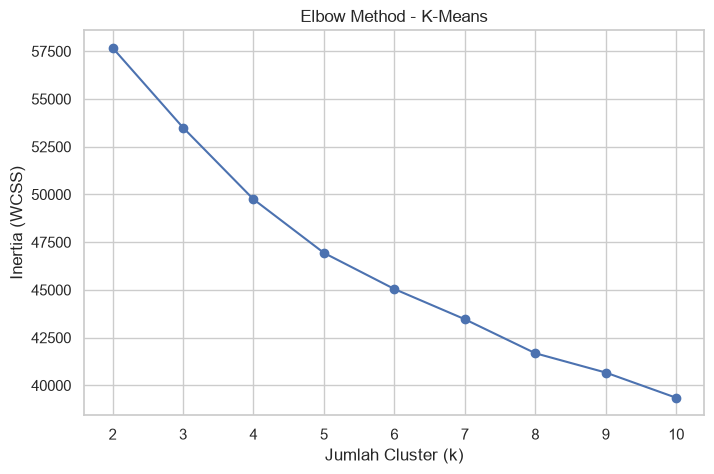

In [80]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker="o"
)

plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Inertia (WCSS)")
plt.title("Elbow Method - K-Means")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

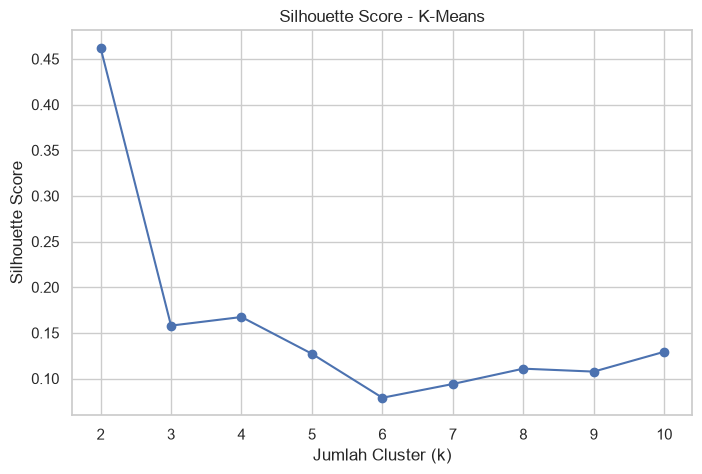

In [81]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    silhouette_values,
    marker="o"
)

plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score - K-Means")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

### 36. Perbandingan Kandidat Jumlah Cluster K-Means

Berdasarkan Elbow Method dan Silhouette Score, diperoleh dua kandidat jumlah cluster, yaitu k=2 dan k=4.

K=2 menghasilkan Silhouette Score tertinggi sebesar 0,4622. Sementara itu, k=4 menjadi kandidat berdasarkan pola penurunan inertia pada Elbow Method.

Kedua kandidat akan dibandingkan menggunakan Adjusted Rand Index (ARI) dan Normalized Mutual Information (NMI) terhadap label referensi BUILDINGID dan FLOOR.

Label referensi hanya digunakan untuk evaluasi, bukan sebagai fitur pembentuk cluster.

In [82]:
from sklearn.metrics import adjusted_rand_score
from sklearn.metrics import normalized_mutual_info_score

k_candidates = [2, 4]
kmeans_comparison = []

kmeans_models = {}
kmeans_labels = {}

for k in k_candidates:

    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_cluster)

    kmeans_models[k] = model
    kmeans_labels[k] = labels

    # Evaluasi terhadap label asli
    ari_building = adjusted_rand_score(
        y_cluster_building, labels
    )

    nmi_building = normalized_mutual_info_score(
        y_cluster_building, labels
    )

    ari_floor = adjusted_rand_score(
        y_cluster_floor, labels
    )

    nmi_floor = normalized_mutual_info_score(
        y_cluster_floor, labels
    )

    kmeans_comparison.append({
        "k": k,
        "ARI Building": ari_building,
        "NMI Building": nmi_building,
        "ARI Floor": ari_floor,
        "NMI Floor": nmi_floor
    })

kmeans_comparison_df = pd.DataFrame(kmeans_comparison)

display(kmeans_comparison_df.round(4))

,k,ARI Building,NMI Building,ARI Floor,NMI Floor
0,2,0.0125,0.0412,0.0014,0.0259
1,4,0.4343,0.5740,-0.0081,0.0344


### Interpretasi Hasil Perbandingan K-Means

Hasil evaluasi menunjukkan bahwa k=4 memiliki kesesuaian yang lebih tinggi terhadap label BUILDINGID dibandingkan k=2. Nilai ARI sebesar 0,4343 dan NMI sebesar 0,5740 menunjukkan adanya hubungan antara hasil clustering dan identitas gedung.

Sebaliknya, kesesuaian kedua kandidat terhadap FLOOR masih rendah. Nilai ARI mendekati nol menunjukkan bahwa hasil pengelompokan belum mampu merepresentasikan struktur lantai secara baik.

Meskipun k=2 menghasilkan Silhouette Score tertinggi sebesar 0,4622, nilai ARI dan NMI terhadap BUILDINGID dan FLOOR relatif rendah.

Dengan mempertimbangkan hasil Elbow Method, Silhouette Score, ARI, dan NMI, k=4 dipertahankan sebagai kandidat utama untuk analisis struktur gedung. Sementara itu, k=2 tetap digunakan sebagai pembanding.

Keputusan akhir akan mempertimbangkan evaluasi internal dan interpretasi fisik cluster.

In [83]:
from sklearn.metrics import davies_bouldin_score

dbi_results = []

for k in [2, 4]:

    labels = kmeans_labels[k]

    dbi = davies_bouldin_score(
        X_cluster,
        labels
    )

    dbi_results.append({
        "k": k,
        "Silhouette Score": silhouette_values[k - 2],
        "Davies-Bouldin Index": dbi
    })

dbi_comparison = pd.DataFrame(dbi_results)

display(dbi_comparison.round(4))

,k,Silhouette Score,Davies-Bouldin Index
0,2,0.4622,0.9414
1,4,0.1674,1.9349


### Interpretasi Evaluasi Internal dan Eksternal K-Means

Berdasarkan evaluasi internal, k=2 menghasilkan Silhouette Score sebesar 0,4622 dan Davies-Bouldin Index sebesar 0,9414. Hasil ini menunjukkan kualitas kekompakan dan pemisahan cluster yang lebih baik dibandingkan k=4.

Namun, evaluasi eksternal menunjukkan bahwa k=4 memiliki kesesuaian lebih tinggi terhadap BUILDINGID, dengan ARI sebesar 0,4343 dan NMI sebesar 0,5740.

Kedua konfigurasi belum menunjukkan kesesuaian yang baik terhadap FLOOR.

Hasil ini menunjukkan adanya perbedaan antara struktur cluster berdasarkan kemiripan RSSI dan struktur lokasi fisik berdasarkan label gedung serta lantai.

Oleh karena itu, k=2 dan k=4 tetap dipertahankan sebagai kandidat untuk analisis lanjutan dan interpretasi fisik cluster.

### 37. Penentuan Parameter DBSCAN Menggunakan K-Distance Plot

DBSCAN merupakan algoritma clustering berbasis kepadatan yang mengelompokkan observasi berdasarkan jarak antar titik dan jumlah minimum observasi di sekitar suatu titik.

Parameter utama yang digunakan adalah:

- eps: radius maksimum lingkungan suatu titik.
- min_samples: jumlah minimum observasi untuk membentuk daerah padat.

Nilai eps dianalisis menggunakan k-distance plot. Titik perubahan kemiringan kurva digunakan sebagai kandidat nilai eps.

Analisis dilakukan menggunakan fitur RSSI yang telah melalui preprocessing dan scaling.

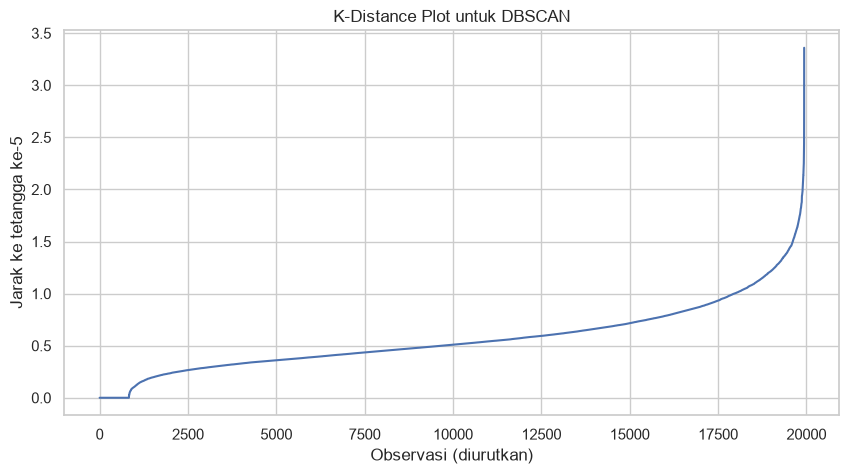

In [84]:
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

# Parameter awal
min_samples_dbscan = 5

# Menghitung jarak ke tetangga terdekat
neighbors = NearestNeighbors(
    n_neighbors=min_samples_dbscan,
    metric="euclidean"
)

neighbors.fit(X_cluster)

distances, indices = neighbors.kneighbors(X_cluster)

# Mengambil jarak tetangga ke-5
k_distances = np.sort(distances[:, -1])

# Visualisasi k-distance plot
plt.figure(figsize=(10, 5))

plt.plot(k_distances)

plt.xlabel("Observasi (diurutkan)")
plt.ylabel("Jarak ke tetangga ke-5")
plt.title("K-Distance Plot untuk DBSCAN")
plt.grid(True)

plt.show()

### 38. Pengujian Kandidat Parameter DBSCAN

Berdasarkan K-distance plot, beberapa kandidat nilai eps diuji untuk memperoleh konfigurasi DBSCAN yang sesuai.

Parameter min_samples ditetapkan sebesar 5 sebagai konfigurasi awal. Kandidat eps yang diuji adalah 1.0, 1.2, 1.4, dan 1.6.

Evaluasi memperhatikan jumlah cluster yang terbentuk, jumlah noise, serta kualitas cluster menggunakan Silhouette Score dan Davies-Bouldin Index.

Observasi yang diklasifikasikan sebagai noise tidak dimasukkan dalam perhitungan metrik internal clustering.

In [85]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.metrics import davies_bouldin_score
import pandas as pd
import numpy as np

eps_candidates = [1.0, 1.2, 1.4, 1.6]
min_samples_dbscan = 5

dbscan_results = []
dbscan_models = {}
dbscan_labels = {}

for eps in eps_candidates:

    model = DBSCAN(
        eps=eps,
        min_samples=min_samples_dbscan,
        metric="euclidean"
    )

    labels = model.fit_predict(X_cluster)

    dbscan_models[eps] = model
    dbscan_labels[eps] = labels

    # Menghitung jumlah cluster tanpa noise
    unique_labels = set(labels)
    n_clusters = len(unique_labels - {-1})

    # Menghitung jumlah noise
    n_noise = np.sum(labels == -1)
    noise_percentage = n_noise / len(labels) * 100

    # Metrik internal hanya untuk observasi non-noise
    non_noise_mask = labels != -1
    X_valid = X_cluster[non_noise_mask]
    labels_valid = labels[non_noise_mask]

    if 1 < len(np.unique(labels_valid)) < len(labels_valid):

        silhouette = silhouette_score(
            X_valid,
            labels_valid,
            sample_size=min(3000, len(X_valid)),
            random_state=42
        )

        dbi = davies_bouldin_score(
            X_valid,
            labels_valid
        )

    else:
        silhouette = np.nan
        dbi = np.nan

    dbscan_results.append({
        "eps": eps,
        "min_samples": min_samples_dbscan,
        "Jumlah Cluster": n_clusters,
        "Jumlah Noise": n_noise,
        "Noise (%)": noise_percentage,
        "Silhouette": silhouette,
        "Davies-Bouldin": dbi
    })

dbscan_comparison = pd.DataFrame(dbscan_results)

display(dbscan_comparison.round(4))

,eps,min_samples,Jumlah Cluster,Jumlah Noise,Noise (%),Silhouette,Davies-Bouldin
0,1.0,5,148,1372,6.8817,-0.0664,0.9102
1,1.2,5,100,616,3.0897,-0.0009,0.8633
2,1.4,5,62,252,1.2640,0.0174,0.8892
3,1.6,5,33,112,0.5618,0.1905,0.8579


### Interpretasi Hasil Pengujian DBSCAN

Berdasarkan pengujian empat kandidat eps dengan min_samples sebesar 5, diperoleh perubahan jumlah cluster dan noise seiring peningkatan nilai eps.

Pada eps=1.0, DBSCAN menghasilkan 148 cluster dengan 6,8817% observasi teridentifikasi sebagai noise. Silhouette Score bernilai negatif, yang menunjukkan kualitas pemisahan cluster belum baik.

Pada eps=1.6, jumlah cluster berkurang menjadi 33 dengan persentase noise sebesar 0,5618%. Konfigurasi ini menghasilkan Silhouette Score tertinggi sebesar 0,1905 dan Davies-Bouldin Index terendah sebesar 0,8579.

Dengan mempertimbangkan kedua metrik internal, eps=1.6 dipilih sebagai kandidat utama untuk evaluasi lanjutan.

Meskipun demikian, konfigurasi ini belum ditetapkan sebagai hasil terbaik secara keseluruhan. Evaluasi eksternal menggunakan ARI dan NMI serta interpretasi fisik cluster tetap diperlukan.

### 39. Evaluasi Eksternal DBSCAN

Evaluasi eksternal dilakukan untuk mengetahui kesesuaian hasil clustering DBSCAN terhadap label referensi BUILDINGID dan FLOOR.

Metrik yang digunakan adalah Adjusted Rand Index (ARI) dan Normalized Mutual Information (NMI).

Seluruh observasi digunakan dalam evaluasi, termasuk observasi yang dikategorikan sebagai noise dengan label -1. Noise diperlakukan sebagai satu kategori tersendiri dalam perhitungan metrik eksternal.

In [86]:
from sklearn.metrics import (
    adjusted_rand_score,
    normalized_mutual_info_score
)

dbscan_external_results = []

for eps in eps_candidates:

    labels = dbscan_labels[eps]

    ari_building = adjusted_rand_score(
        y_cluster_building,
        labels
    )

    nmi_building = normalized_mutual_info_score(
        y_cluster_building,
        labels
    )

    ari_floor = adjusted_rand_score(
        y_cluster_floor,
        labels
    )

    nmi_floor = normalized_mutual_info_score(
        y_cluster_floor,
        labels
    )

    dbscan_external_results.append({
        "eps": eps,
        "ARI Building": ari_building,
        "NMI Building": nmi_building,
        "ARI Floor": ari_floor,
        "NMI Floor": nmi_floor
    })

dbscan_external_df = pd.DataFrame(
    dbscan_external_results
)

display(dbscan_external_df.round(4))

,eps,ARI Building,NMI Building,ARI Floor,NMI Floor
0,1.0,0.1903,0.2619,0.0143,0.1436
1,1.2,0.0431,0.1194,0.0075,0.1197
2,1.4,0.0326,0.0920,-0.0017,0.0762
3,1.6,0.0236,0.0710,-0.0000,0.0550


### Interpretasi Hasil Evaluasi Eksternal DBSCAN

Berdasarkan evaluasi eksternal, eps=1.0 menghasilkan nilai ARI dan NMI tertinggi terhadap BUILDINGID, masing-masing sebesar 0,1903 dan 0,2619.

Konfigurasi tersebut juga menghasilkan nilai ARI dan NMI FLOOR tertinggi dibandingkan kandidat eps lainnya. Namun, nilai ARI FLOOR sebesar 0,0143 masih menunjukkan kesesuaian yang sangat rendah.

Sementara itu, eps=1.6 memiliki kualitas internal terbaik berdasarkan Silhouette Score dan Davies-Bouldin Index, tetapi kesesuaiannya terhadap label asli lebih rendah.

Hasil ini menunjukkan adanya trade-off antara kualitas internal cluster dan kesesuaian terhadap label lokasi sebenarnya.

Oleh karena itu, eps=1.0 dan eps=1.6 dipertahankan sebagai dua konfigurasi pembanding untuk analisis lanjutan.

### 40. Visualisasi Cluster Menggunakan PCA 2D

Principal Component Analysis (PCA) digunakan untuk mereduksi dimensi data menjadi dua komponen utama agar hasil clustering dapat divisualisasikan dalam bidang dua dimensi.

PCA hanya digunakan untuk visualisasi. Proses clustering tetap menggunakan seluruh fitur RSSI hasil preprocessing.

Visualisasi dilakukan untuk membandingkan struktur cluster K-Means dan DBSCAN.

In [87]:
from sklearn.decomposition import PCA

# PCA untuk visualisasi 2D
pca = PCA(
    n_components=2,
    random_state=42
)

X_pca = pca.fit_transform(X_cluster)

print("Dimensi PCA:", X_pca.shape)

print(
    "Total explained variance ratio:",
    round(pca.explained_variance_ratio_.sum(), 4)
)

Dimensi PCA: (19937, 2)
Total explained variance ratio: 0.1676


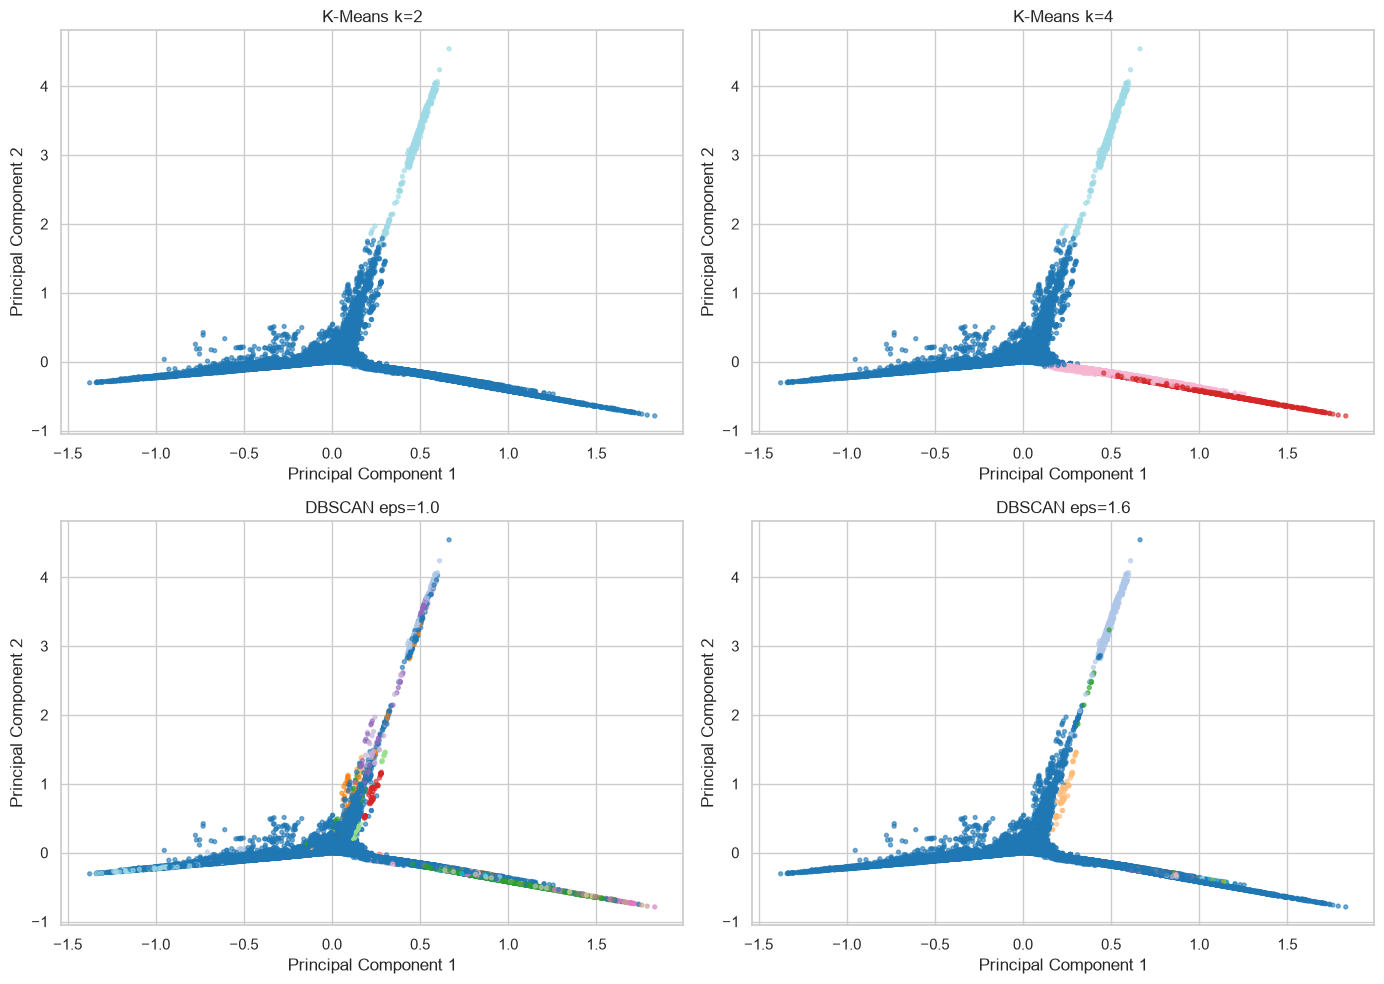

In [88]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

cluster_configs = [
    ("K-Means k=2", kmeans_labels[2]),
    ("K-Means k=4", kmeans_labels[4]),
    ("DBSCAN eps=1.0", dbscan_labels[1.0]),
    ("DBSCAN eps=1.6", dbscan_labels[1.6])
]

for ax, (title, labels) in zip(
    axes.flatten(),
    cluster_configs
):
    scatter = ax.scatter(
        X_pca[:, 0],
        X_pca[:, 1],
        c=labels,
        cmap="tab20",
        s=8,
        alpha=0.6
    )

    ax.set_title(title)
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")

plt.tight_layout()
plt.show()

### Interpretasi Visualisasi PCA 2D

Hasil PCA menghasilkan dua komponen utama dengan total explained variance ratio sebesar 16,76%. Artinya, kedua komponen tersebut hanya merepresentasikan sebagian variasi dari keseluruhan fitur RSSI.

Pada K-Means k=2, data terbagi menjadi dua kelompok besar. Pada k=4, pembagian cluster menjadi lebih terperinci.

DBSCAN eps=1.0 menghasilkan banyak kelompok kecil, sedangkan eps=1.6 menghasilkan jumlah cluster yang lebih sedikit dengan lebih banyak observasi tergabung dalam kelompok yang lebih besar.

Visualisasi PCA digunakan untuk membantu mengamati pola distribusi cluster. Karena proporsi variasi yang dijelaskan hanya 16,76%, interpretasi visual tidak digunakan sebagai satu-satunya dasar untuk menentukan kualitas clustering.

Evaluasi tetap mempertimbangkan Silhouette Score, Davies-Bouldin Index, ARI, dan NMI.

### 41. Interpretasi Fisik Cluster K-Means

Interpretasi fisik dilakukan dengan menganalisis hubungan antara hasil clustering dan karakteristik lokasi sebenarnya.

Analisis mencakup distribusi BUILDINGID, FLOOR, LONGITUDE, dan LATITUDE pada setiap cluster.

Label asli tidak digunakan dalam pembentukan cluster, tetapi digunakan untuk memahami karakteristik geografis dan posisi fisik kelompok yang terbentuk.

In [89]:
# Membuat dataframe interpretasi cluster K-Means

cluster_analysis = pd.DataFrame({
    "BUILDINGID": y_cluster_building,
    "FLOOR": y_cluster_floor,
    "LONGITUDE": y_train["LONGITUDE"].reset_index(drop=True),
    "LATITUDE": y_train["LATITUDE"].reset_index(drop=True)
})

# Menambahkan label cluster
cluster_analysis["KMeans_k2"] = kmeans_labels[2]
cluster_analysis["KMeans_k4"] = kmeans_labels[4]

# Profil distribusi gedung untuk K-Means k=4
print("=== DISTRIBUSI BUILDINGID PER CLUSTER ===")

display(
    pd.crosstab(
        cluster_analysis["KMeans_k4"],
        cluster_analysis["BUILDINGID"],
        normalize="index"
    ).round(3)
)

# Profil distribusi lantai untuk K-Means k=4
print("=== DISTRIBUSI FLOOR PER CLUSTER ===")

display(
    pd.crosstab(
        cluster_analysis["KMeans_k4"],
        cluster_analysis["FLOOR"],
        normalize="index"
    ).round(3)
)

# Rata-rata koordinat setiap cluster
print("=== RATA-RATA KOORDINAT PER CLUSTER ===")

display(
    cluster_analysis.groupby("KMeans_k4")[
        ["LONGITUDE", "LATITUDE"]
    ].mean().round(6)
)

=== DISTRIBUSI BUILDINGID PER CLUSTER ===


BUILDINGID,0,1,2
KMeans_k4,,,
0,0.015,0.333,0.652
1,1.000,0.000,0.000
2,1.000,0.000,0.000
3,0.000,1.000,0.000


=== DISTRIBUSI FLOOR PER CLUSTER ===


FLOOR,0,1,2,3,4
KMeans_k4,,,,,
0,0.215,0.250,0.206,0.254,0.076
1,0.192,0.265,0.270,0.273,0.000
2,0.175,0.265,0.295,0.264,0.000
3,0.904,0.096,0.000,0.000,0.000


=== RATA-RATA KOORDINAT PER CLUSTER ===


,LONGITUDE,LATITUDE
KMeans_k4,,
0,-7403.841115,4.864842e+06
1,-7657.062828,4.864927e+06
2,-7622.360373,4.864988e+06
3,-7456.350020,4.864827e+06


### Interpretasi Fisik Cluster K-Means k=4

Berdasarkan distribusi BUILDINGID, cluster 1 dan cluster 2 seluruhnya berasal dari Building 0. Cluster 3 seluruhnya berasal dari Building 1, sedangkan cluster 0 didominasi Building 2 sebesar 65,2%.

Hasil ini menunjukkan bahwa K-Means mampu membentuk beberapa kelompok yang memiliki keterkaitan dengan identitas gedung. Namun, cluster 0 masih mencampurkan observasi dari beberapa gedung.

Berdasarkan distribusi FLOOR, cluster 3 didominasi oleh FLOOR 0 sebesar 90,4%. Sementara itu, cluster 1 dan cluster 2 memiliki distribusi lantai yang relatif merata pada FLOOR 0 sampai FLOOR 3.

Hasil ini menunjukkan bahwa pemisahan berdasarkan lantai belum terbentuk secara konsisten.

Rata-rata longitude dan latitude juga menunjukkan perbedaan posisi antarcluster. Namun, interpretasi geografis lebih lanjut memerlukan pemeriksaan sistem koordinat dan sebaran koordinat setiap cluster.

Secara keseluruhan, K-Means k=4 mampu menangkap sebagian struktur lokasi berdasarkan gedung, tetapi belum sepenuhnya memisahkan karakteristik lantai.

In [90]:
# Menambahkan label cluster DBSCAN

cluster_analysis["DBSCAN_eps1"] = dbscan_labels[1.0]
cluster_analysis["DBSCAN_eps1_6"] = dbscan_labels[1.6]


def analyze_dbscan_clusters(data, cluster_column):

    print(f"\n=== {cluster_column}: BUILDINGID ===")

    display(
        pd.crosstab(
            data[cluster_column],
            data["BUILDINGID"],
            normalize="index"
        ).round(3)
    )

    print(f"\n=== {cluster_column}: FLOOR ===")

    display(
        pd.crosstab(
            data[cluster_column],
            data["FLOOR"],
            normalize="index"
        ).round(3)
    )

    print(f"\n=== {cluster_column}: KOORDINAT ===")

    display(
        data.groupby(cluster_column)[
            ["LONGITUDE", "LATITUDE"]
        ].mean().round(3)
    )


analyze_dbscan_clusters(
    cluster_analysis,
    "DBSCAN_eps1"
)

analyze_dbscan_clusters(
    cluster_analysis,
    "DBSCAN_eps1_6"
)


=== DBSCAN_eps1: BUILDINGID ===


BUILDINGID,0,1,2
DBSCAN_eps1,,,
-1,0.585,0.166,0.249
0,0.128,0.282,0.589
1,0.000,0.000,1.000
2,0.000,1.000,0.000
3,0.000,1.000,0.000
...,...,...,...
143,0.000,0.000,1.000
144,0.000,0.000,1.000
145,0.000,0.000,1.000



=== DBSCAN_eps1: FLOOR ===


FLOOR,0,1,2,3,4
DBSCAN_eps1,,,,,
-1,0.075,0.347,0.321,0.246,0.012
0,0.238,0.238,0.213,0.269,0.042
1,0.000,0.000,0.000,1.000,0.000
2,0.000,0.000,1.000,0.000,0.000
3,0.000,0.000,1.000,0.000,0.000
...,...,...,...,...,...
143,0.000,1.000,0.000,0.000,0.000
144,0.000,1.000,0.000,0.000,0.000
145,0.000,1.000,0.000,0.000,0.000



=== DBSCAN_eps1: KOORDINAT ===


,LONGITUDE,LATITUDE
DBSCAN_eps1,,
-1,-7537.279,4864911.100
0,-7427.912,4864859.185
1,-7329.027,4864766.304
2,-7458.264,4864852.084
3,-7507.032,4864834.894
...,...,...
143,-7320.132,4864816.324
144,-7338.259,4864821.407
145,-7331.117,4864821.621


... (2 outputs left out)


=== DBSCAN_eps1_6: FLOOR ===


FLOOR,0,1,2,3,4
DBSCAN_eps1_6,,,,,
-1,0.089,0.196,0.652,0.062,0.000
0,0.212,0.250,0.221,0.260,0.057
1,0.966,0.034,0.000,0.000,0.000
2,0.000,1.000,0.000,0.000,0.000
3,0.000,1.000,0.000,0.000,0.000
4,1.000,0.000,0.000,0.000,0.000
5,0.000,1.000,0.000,0.000,0.000
6,1.000,0.000,0.000,0.000,0.000
7,0.000,1.000,0.000,0.000,0.000



=== DBSCAN_eps1_6: KOORDINAT ===


,LONGITUDE,LATITUDE
DBSCAN_eps1_6,,
-1,-7560.922,4864939.782
0,-7461.879,4864870.146
1,-7456.262,4864825.645
2,-7312.583,4864797.237
3,-7328.049,4864766.951
4,-7499.118,4864838.798
5,-7506.735,4864857.355
6,-7458.241,4864850.011
7,-7638.904,4864999.541


In [91]:
# Ringkasan ukuran cluster DBSCAN

def summarize_dbscan_clusters(data, cluster_column):

    summary = (
        data.groupby(cluster_column)
        .agg(
            Jumlah_Data=("BUILDINGID", "size"),
            Building_Dominan=(
                "BUILDINGID",
                lambda x: x.mode().iloc[0]
            ),
            Floor_Dominan=(
                "FLOOR",
                lambda x: x.mode().iloc[0]
            ),
            Persentase_Building_Dominan=(
                "BUILDINGID",
                lambda x: x.value_counts(normalize=True).max() * 100
            ),
            Persentase_Floor_Dominan=(
                "FLOOR",
                lambda x: x.value_counts(normalize=True).max() * 100
            )
        )
        .sort_values("Jumlah_Data", ascending=False)
    )

    summary["Jumlah_Data"] = summary["Jumlah_Data"].astype(int)

    return summary.round(2)


print("=== RINGKASAN DBSCAN EPS 1.0 ===")
display(
    summarize_dbscan_clusters(
        cluster_analysis,
        "DBSCAN_eps1"
    )
)

print("=== RINGKASAN DBSCAN EPS 1.6 ===")
display(
    summarize_dbscan_clusters(
        cluster_analysis,
        "DBSCAN_eps1_6"
    )
)

=== RINGKASAN DBSCAN EPS 1.0 ===


,Jumlah_Data,Building_Dominan,Floor_Dominan,Persentase_Building_Dominan,Persentase_Floor_Dominan
DBSCAN_eps1,,,,,
0,14422,2,3,58.93,26.94
34,2002,0,1,100.00,25.77
-1,1372,0,1,58.53,34.69
54,230,2,4,100.00,100.00
53,210,2,4,100.00,100.00
...,...,...,...,...,...
135,5,0,2,100.00,100.00
140,5,0,3,100.00,100.00
141,5,0,3,100.00,100.00


=== RINGKASAN DBSCAN EPS 1.6 ===


,Jumlah_Data,Building_Dominan,Floor_Dominan,Persentase_Building_Dominan,Persentase_Floor_Dominan
DBSCAN_eps1_6,,,,,
0,19172,2,3,49.29,26.03
1,293,1,0,100.00,96.59
5,126,1,1,100.00,100.00
-1,112,0,2,71.43,65.18
6,10,1,0,100.00,100.00
7,10,0,1,100.00,100.00
8,10,0,1,100.00,100.00
9,10,0,1,100.00,100.00
16,10,0,2,100.00,100.00


### Interpretasi Fisik Cluster DBSCAN

Pada eps=1.0, cluster terbesar berisi 14.422 observasi atau sekitar 72,34% dari keseluruhan data. Cluster 34 berisi 2.002 observasi dan seluruhnya berasal dari Building 0. Namun, konfigurasi ini menghasilkan 148 cluster dan persentase noise sebesar 6,88%, sehingga menunjukkan fragmentasi kelompok yang cukup tinggi.

Pada eps=1.6, cluster terbesar berisi 19.172 observasi atau sekitar 96,16% dari keseluruhan data. Beberapa cluster kecil menunjukkan kesesuaian yang kuat terhadap gedung dan lantai tertentu. Namun, dominasi satu cluster besar menunjukkan bahwa sebagian besar observasi belum terpisah menjadi kelompok yang lebih spesifik.

Dengan demikian, eps=1.0 memiliki kesesuaian lebih tinggi terhadap BUILDINGID berdasarkan ARI dan NMI, sedangkan eps=1.6 memiliki kualitas internal lebih baik berdasarkan Silhouette Score dan Davies-Bouldin Index.

Kedua konfigurasi memiliki keterbatasan dalam merepresentasikan struktur lokasi indoor secara menyeluruh. Hasil clustering perlu diinterpretasikan dengan mempertimbangkan ukuran cluster, distribusi gedung, distribusi lantai, dan jumlah noise.

### 42. Perbandingan Hasil K-Means dan DBSCAN

Perbandingan dilakukan untuk mengevaluasi kualitas clustering berdasarkan metrik internal dan eksternal.

Metrik internal meliputi Silhouette Score dan Davies-Bouldin Index. Metrik eksternal meliputi Adjusted Rand Index (ARI) dan Normalized Mutual Information (NMI) terhadap BUILDINGID dan FLOOR.

Selain itu, jumlah cluster dan noise digunakan untuk memahami karakteristik pengelompokan masing-masing algoritma.

Perbandingan ini bertujuan mengidentifikasi kelebihan dan keterbatasan setiap konfigurasi dalam merepresentasikan struktur lokasi indoor berdasarkan fingerprint RSSI Wi-Fi.

In [92]:
# Tabel perbandingan akhir K-Means dan DBSCAN

final_clustering_comparison = pd.DataFrame([
    {
        "Algorithm": "K-Means",
        "Configuration": "k=2",
        "Clusters": 2,
        "Noise (%)": 0,
        "Silhouette": 0.4622,
        "Davies-Bouldin": 0.9414,
        "ARI Building": 0.0125,
        "NMI Building": 0.0412,
        "ARI Floor": 0.0014,
        "NMI Floor": 0.0259
    },
    {
        "Algorithm": "K-Means",
        "Configuration": "k=4",
        "Clusters": 4,
        "Noise (%)": 0,
        "Silhouette": 0.1674,
        "Davies-Bouldin": 1.9349,
        "ARI Building": 0.4343,
        "NMI Building": 0.5740,
        "ARI Floor": -0.0081,
        "NMI Floor": 0.0344
    },
    {
        "Algorithm": "DBSCAN",
        "Configuration": "eps=1.0",
        "Clusters": 148,
        "Noise (%)": 6.8817,
        "Silhouette": -0.0664,
        "Davies-Bouldin": 0.9102,
        "ARI Building": 0.1903,
        "NMI Building": 0.2619,
        "ARI Floor": 0.0143,
        "NMI Floor": 0.1436
    },
    {
        "Algorithm": "DBSCAN",
        "Configuration": "eps=1.6",
        "Clusters": 33,
        "Noise (%)": 0.5618,
        "Silhouette": 0.1905,
        "Davies-Bouldin": 0.8579,
        "ARI Building": 0.0236,
        "NMI Building": 0.0710,
        "ARI Floor": 0.0000,
        "NMI Floor": 0.0550
    }
])

display(final_clustering_comparison.round(4))

,Algorithm,Configuration,Clusters,Noise (%),Silhouette,Davies-Bouldin,ARI Building,NMI Building,ARI Floor,NMI Floor
0,K-Means,k=2,2,0.0000,0.4622,0.9414,0.0125,0.0412,0.0014,0.0259
1,K-Means,k=4,4,0.0000,0.1674,1.9349,0.4343,0.5740,-0.0081,0.0344
2,DBSCAN,eps=1.0,148,6.8817,-0.0664,0.9102,0.1903,0.2619,0.0143,0.1436
3,DBSCAN,eps=1.6,33,0.5618,0.1905,0.8579,0.0236,0.0710,0.0000,0.0550


### 43. Kesimpulan Hasil Clustering

Berdasarkan eksperimen K-Means dan DBSCAN, kedua algoritma menunjukkan karakteristik pengelompokan yang berbeda pada dataset fingerprint RSSI Wi-Fi UJIIndoorLoc.

K-Means k=2 menghasilkan kualitas internal terbaik dengan Silhouette Score sebesar 0,4622 dan Davies-Bouldin Index sebesar 0,9414. Namun, kesesuaian cluster terhadap label BUILDINGID masih rendah.

K-Means k=4 menghasilkan kesesuaian tertinggi terhadap BUILDINGID dengan ARI sebesar 0,4343 dan NMI sebesar 0,5740. Hasil interpretasi fisik juga menunjukkan bahwa beberapa cluster memiliki dominasi gedung tertentu. Namun, pemisahan berdasarkan FLOOR masih belum optimal.

Pada DBSCAN, eps=1.0 menghasilkan kesesuaian eksternal lebih tinggi dibandingkan eps=1.6, khususnya terhadap BUILDINGID. Akan tetapi, konfigurasi tersebut menghasilkan banyak cluster kecil. Sementara itu, eps=1.6 memiliki kualitas internal lebih baik, tetapi sebagian besar observasi terkumpul dalam satu cluster besar.

Secara keseluruhan, K-Means k=4 menjadi konfigurasi yang paling menjanjikan untuk merepresentasikan struktur gedung berdasarkan label referensi. K-Means k=2 tetap unggul dalam kualitas internal, sedangkan DBSCAN memberikan gambaran kelompok berbasis kepadatan dan observasi noise.

Hasil clustering menunjukkan bahwa kemiripan fingerprint RSSI tidak selalu menghasilkan kelompok yang sepenuhnya sesuai dengan identitas gedung dan lantai sebenarnya. Hal ini menunjukkan adanya kompleksitas karakteristik sinyal Wi-Fi pada lingkungan indoor.

Catatan metodologis: metrik internal K-Means dan DBSCAN tidak sepenuhnya setara karena DBSCAN mengecualikan noise, sedangkan K-Means tidak memiliki noise. Oleh karena itu, tidak boleh menganggap perbandingan angka metrik internal sebagai perbandingan yang sepenuhnya setara.